# Filtered aperture E/B shear maps on HEALPix (DP2, PSZ2 G309.43-72.86, tract 2877)

Alex Broughton · October 2026. Rubin stack and Butler access required.


## Introduction

Schirmer-filtered aperture E- and B-mode shear maps on HEALPix for DP2 tract 2877, which contains the Planck SZ cluster
PSZ2 G309.43-72.86 (RA, Dec = 10.2082°, −44.1307°). By position this is SPT-CL J0040-4407 (z = 0.35,
M200 ≈ 1.4×10¹⁵ M⊙, r200 ≈ 2.0 Mpc ≈ 6.9′). Shapes are HSM regauss from the object table. These are weighted aperture
statistics, not a Kaiser-Squires reconstruction.

- E-mode: tangential shear g_t weighted by the Schirmer filter Q.
- B-mode: cross shear g× weighted by the same Q; consistent with zero for pure lensing.
- Geometry: every HEALPix cell containing a source in the target tract is evaluated at its center. Galaxies from
  neighboring tracts are included so apertures are complete at the tract edge.
- Shear frame: HSM e2 is defined in the coadd pixel frame and is sign-flipped into the RA/Dec frame.
- Dust: griz magnitudes are corrected for Milky Way extinction before any color cut, using the Object-table `ebv`
  column (SFD98) and the Rubin R_band coefficients (section 3.0).
- Weights: inverse variance, intrinsic shape noise plus measurement error squared.
- Filter and cells: Rs = 15′, x_c = 0.15, NSIDE = 4096 (0.86′ cells), justified in section 7.
- Peaks: S/N maxima within 0.4 Rs, aperture completeness ≥ 0.8, S/N ≥ 4.

## 1.0 Setup

### 1.1 Imports and configuration

All tunable quantities live in the CONFIG dictionary.

In [1]:
import gc
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import astropy.units as u
from astropy.table import Table, vstack
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

# The Rubin stack is optional: without it a saved local object table is read instead.
try:
    from lsst.daf.butler import Butler
    from lsst.sphgeom import Angle as SphAngle, Circle
    from lsst.geom import SpherePoint, degrees
    HAVE_LSST = True
except ImportError:
    HAVE_LSST = False
    print("Rubin stack not found: using CONFIG['LOCAL_TABLE'] instead of the Butler")

%matplotlib inline
plt.rcParams.update({"font.size": 12})


# Repo layout: _data/ holds external inputs, output/ holds generated tables/catalogs, plots/ holds figures.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "_data"
OUTPUT_DIR = ROOT / "output"
PLOTS_DIR = ROOT / "plots"
for _d in (OUTPUT_DIR, PLOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_plot(fig, name):
    fig.savefig(PLOTS_DIR / f"{name}.pdf", bbox_inches="tight")


def mark_cluster(ax, label=True, color="k"):
    """Mark CLUSTER on an RA/Dec axis with a star and, optionally, its name."""
    ax.scatter(CLUSTER["ra"], CLUSTER["dec"], marker="*", s=250, facecolors="none",
               edgecolors=color, linewidths=1.5, zorder=5, label=CLUSTER["name"])
    if label:
        ax.annotate(CLUSTER["name"], (CLUSTER["ra"], CLUSTER["dec"]), xytext=(8, 8),
                    textcoords="offset points", fontsize=10, color=color,
                    bbox=dict(boxstyle="round,pad=0.2", fc="w", ec="none", alpha=0.7))


def tract_area_deg2(skymap, tract):
    """Area of a tract's unique (inner) region in deg^2."""
    region = skymap[tract].inner_sky_region
    if hasattr(region, "getArea"):  # sphgeom.Box, as in rings skymaps
        sr = region.getArea()
    else:  # convex polygon: sum the solid angles of a triangle fan
        v = np.array([[p.x(), p.y(), p.z()] for p in region.getVertices()])
        a = v[0]
        sr = sum(
            2 * np.arctan2(abs(a @ np.cross(b, c)), 1 + a @ b + b @ c + c @ a)
            for b, c in zip(v[1:-1], v[2:])
        )
    return float(sr * (180.0 / np.pi) ** 2)

Rubin stack not found: using CONFIG['LOCAL_TABLE'] instead of the Butler


/sessions/focused-zen-clarke/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CONFIG = {
    "REPO": "/sdf/data/rubin/repo/dp2_prep",  # Butler repository root
    "COLLECTION": "LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3",  # Input collection
    "SKYMAP": "lsst_cells_v2",  # Skymap name for Butler
    "INSTRUMENT": "LSSTCam",  # Instrument dimension
    "TRACT": 2877,  # Contains PSZ2 G309.43-72.86
    # Saved copy of the tract-2877 object table, used when the Rubin stack is not importable.
    "LOCAL_TABLE": DATA_DIR / "data_PSZ2_G309.43-72.86_tract-2877.fits",
    # --- Filter, cell, and peak settings ---
    "RS_INPUT_PIX": 4500,  # Schirmer aperture radius Rs in native pixels: 4500 x 0.2" = 15'
    "PIX_SCALE_ARCSEC": 0.2,  # Arcsec per pixel (converts RS_INPUT_PIX to sky angle)
    "FILTER_XC": 0.15,  # Schirmer core x_c (NFW-optimized value; the data cannot tell 0.05-0.3 apart)
    "SEARCH_RADIUS_RS_MULT": 1.2,  # Search radius in units of Rs; Q(x) is zero for x > ~1.1
    "NSIDE": int(2**12),  # HEALPix NSIDE (RING), 0.86' cells: worst-case loss 0.7 sigma at the peak
    "PEAK_SN_MIN": 4.0,  # Peak S/N cut, above the random-rotation noise peaks; None disables
    "PEAK_EXCL_RS_MULT": 0.4,  # A peak is the S/N maximum within this many Rs (noise decorrelation length)
    "PEAK_COMPLETENESS_MIN": 0.8,  # Minimum aperture completeness (counts / expected counts)
    "N_RANDOM": 10,  # Random-rotation noise realizations computed alongside the map
    "RANDOM_SEED": 42,
    # --- Shear frame and weights ---
    "E2_SIGN": -1,  # HSM e2 is in the coadd pixel frame (x toward -RA): flip it into the RA/Dec frame
    "SHAPE_NOISE_E": None,  # Intrinsic per-component distortion dispersion; None measures it from the catalog
    # Source selection, following selection_cuts.md.
    "SNR_MIN": 5.0,  # Minimum per-band griz Sersic flux S/N
    "RESO_FACTOR_MIN": 0.125,  # Minimum PSF-resolution factor (star-galaxy separation)
    "COLOR_ABS_MAX": 5.0,  # Maximum |g-r|, |r-i|, |i-z| in AB magnitudes
    "EXTENDEDNESS_MIN": 0.2,  # Minimum griz model extendedness
    "E_SQ_MAX": 4.0,  # Maximum e1^2 + e2^2 for the HSM regauss distortion
    "T_MAX_ARCSEC2": None,  # Optional size cut on i_ixx + i_iyy; None disables it
    "RED_SEQ_SLOPE": 2.0484,  # Red-sequence line: g-i = slope * (r-z) + intercept
    "RED_SEQ_INTERCEPT": -0.10,  # Objects above that line are rejected (dereddened colors when DEREDDEN)
    # Milky Way dust correction, following Rubin tutorial 311.1: m_0 = m - R_band * E(B-V), with E(B-V)
    # from the Object-table ebv column (SFD98). All color cuts use the corrected magnitudes.
    "DEREDDEN": True,
    "EBV_COLUMN": "ebv",
    # R_band = A_band / E(B-V) from rubin_sim DustValues().r_x: CCM89, R_V = 3.1, flat SED, LSST baseline
    # throughputs (rubin_sim 2.6.2, throughputs_2025_08_25).
    "EXTINCTION_R": {"u": 4.757, "g": 3.661, "r": 2.701, "i": 2.054, "z": 1.590, "y": 1.308},
}

# Target cluster, with literature values for SPT-CL J0040-4407.
CLUSTER = {"name": "PSZ2 G309.43-72.86", "ra": 10.2082, "dec": -44.1307,
           "z": 0.35, "M200": 1.4e15, "c200": 4.0}

USE_BUTLER = HAVE_LSST

# Filter scale Rs expressed in the angular units needed downstream.
CONFIG["RS_ARCSEC"] = float(CONFIG["RS_INPUT_PIX"]) * float(CONFIG["PIX_SCALE_ARCSEC"])
CONFIG["RS_ARCMIN"] = CONFIG["RS_ARCSEC"] / 60.0
CONFIG["RS_DEG"] = CONFIG["RS_ARCSEC"] / 3600.0

# Aperture radius used for the neighbor search around each HEALPix cell center.
CONFIG["THETA_MAX_ARCMIN"] = float(CONFIG["SEARCH_RADIUS_RS_MULT"]) * CONFIG["RS_ARCMIN"]
CONFIG["NSIDE"] = int(CONFIG["NSIDE"])

# Mean HEALPix pixel spacing, i.e. sqrt(pixel area), as a sanity check against Rs.
_mean_arcsec = float(np.rad2deg((4.0 * np.pi / 12.0) ** 0.5 / CONFIG["NSIDE"]) * 3600.0)
_npix = hp.nside2npix(CONFIG["NSIDE"])

print("TRACT =", CONFIG["TRACT"], "| data source:", "Butler" if USE_BUTLER else CONFIG["LOCAL_TABLE"].name)
print(f"Cluster {CLUSTER['name']}: RA={CLUSTER['ra']}, Dec={CLUSTER['dec']}")
print(
    "Schirmer Rs =",
    CONFIG["RS_INPUT_PIX"],
    "pix @",
    CONFIG["PIX_SCALE_ARCSEC"],
    "arcsec/pix →",
    f"{CONFIG['RS_ARCMIN']:.3f} arcmin, x_c = {CONFIG['FILTER_XC']}",
)
print(
    "search radius THETA_MAX_ARCMIN =",
    f"{CONFIG['THETA_MAX_ARCMIN']:.3f}",
    f"({CONFIG['SEARCH_RADIUS_RS_MULT']}×Rs) | NSIDE =",
    CONFIG["NSIDE"],
    f"(npix={_npix}; ~mean spacing {_mean_arcsec:.1f} arcsec)",
)

TRACT = 2877 | data source: data_PSZ2_G309.43-72.86_tract-2877.fits
Cluster PSZ2 G309.43-72.86: RA=10.2082, Dec=-44.1307
Schirmer Rs = 4500 pix @ 0.2 arcsec/pix → 15.000 arcmin, x_c = 0.15
search radius THETA_MAX_ARCMIN = 18.000 (1.2×Rs) | NSIDE = 4096 (npix=201326592; ~mean spacing 51.5 arcsec)


In [3]:
# Butler client for the repo/collection defined above (skipped in local-table mode).
butler = None
if USE_BUTLER:
    butler = Butler(
        CONFIG["REPO"],
        collections=[CONFIG["COLLECTION"]],
        skymap=CONFIG["SKYMAP"],
        instrument=CONFIG["INSTRUMENT"],
    )

### 1.2 Table helpers

In [4]:
def _col(tbl, name):
    """Column as a float64 numpy array."""
    return np.array(tbl[name]).astype(np.float64, copy=False)


def flux_to_abmag(flux_njy):
    """Convert nJy fluxes to AB magnitudes; non-positive or non-finite fluxes become NaN."""
    flux = np.asarray(flux_njy, dtype=np.float64)
    mag = np.full(flux.shape, np.nan, dtype=np.float64)
    good = np.isfinite(flux) & (flux > 0.0)
    mag[good] = (flux[good] * u.nJy).to(u.ABmag).value
    return mag


def griz_mags(tbl):
    """griz AB magnitudes from the Sersic fluxes, dust-corrected when CONFIG["DEREDDEN"] is set.

    m_0 = m - R_band * E(B-V). Objects with a non-finite E(B-V) get NaN magnitudes and fail the color cuts.
    """
    mags = {b: flux_to_abmag(_col(tbl, f"{b}_sersicFlux")) for b in "griz"}
    if not CONFIG["DEREDDEN"]:
        return mags
    ebv_col = CONFIG["EBV_COLUMN"]
    if ebv_col not in tbl.colnames:
        raise KeyError(
            f"CONFIG['DEREDDEN'] is set but the table has no '{ebv_col}' column. Read it from the Butler, "
            "re-save the local table with it, or set CONFIG['DEREDDEN'] = False."
        )
    ebv = _col(tbl, ebv_col)
    return {b: m - CONFIG["EXTINCTION_R"][b] * ebv for b, m in mags.items()}


FLAG_COLUMNS = [
    "i_i_flag",
    "i_iPSF_flag",
    "i_hsmShapeRegauss_flag",
    "i_gaapFlux_flag",
    "sersic_no_data_flag",
    "sersic_unknown_flag",
    "shape_flag",
    "i_pixelFlags_bad",
    "i_pixelFlags_nodata",
    "i_pixelFlags_edge",
    "i_pixelFlags_saturatedCenter",
    "i_pixelFlags_crCenter",
    "i_pixelFlags_interpolatedCenter",
    "i_pixelFlags_suspectCenter",
]

OBJECT_COLUMNS = [
    "objectId",
    "coord_ra",
    "coord_dec",
    "ebv",  # SFD98 E(B-V) at the object position, for the dust correction
    "detect_isDeblendedModelSource",
    "griz_model_extendedness",
    "i_hsmShapeRegauss_e1",
    "i_hsmShapeRegauss_e2",
    "i_hsmShapeRegauss_sigma",
    "i_ixx",
    "i_iyy",
    "i_ixxPSF",
    "i_iyyPSF",
    "i_inputCount",
    "g_sersicFlux",
    "g_sersicFluxErr",
    "r_sersicFlux",
    "r_sersicFluxErr",
    "i_sersicFlux",
    "i_sersicFluxErr",
    "z_sersicFlux",
    "z_sersicFluxErr",
] + FLAG_COLUMNS

SHEAR_COLUMNS = [
    "objectId",
    "coord_ra",
    "coord_dec",
    "i_hsmShapeRegauss_e1",
    "i_hsmShapeRegauss_e2",
    "i_hsmShapeRegauss_sigma",
]


def selection_mask(data):
    """Combined selection mask and the per-group masks that build it."""
    n = len(data)
    flag_columns = [c for c in FLAG_COLUMNS if c in data.colnames]

    flags_ok = np.ones(n, dtype=bool)
    for name in flag_columns:
        flags_ok &= ~np.asarray(data[name], dtype=bool)
    if "i_inputCount" in data.colnames:
        flags_ok &= np.asarray(data["i_inputCount"]) > 0

    primary_ok = np.asarray(data["detect_isDeblendedModelSource"], dtype=bool)

    e_sq = _col(data, "i_hsmShapeRegauss_e1") ** 2 + _col(data, "i_hsmShapeRegauss_e2") ** 2
    shape_ok = e_sq <= CONFIG["E_SQ_MAX"]

    t_obj = _col(data, "i_ixx") + _col(data, "i_iyy")
    with np.errstate(divide="ignore", invalid="ignore"):
        reso = 1.0 - (_col(data, "i_ixxPSF") + _col(data, "i_iyyPSF")) / t_obj
    reso_ok = reso > CONFIG["RESO_FACTOR_MIN"]

    mag = griz_mags(data)  # dust-corrected when CONFIG["DEREDDEN"]
    with np.errstate(divide="ignore", invalid="ignore"):
        snr = {b: _col(data, f"{b}_sersicFlux") / _col(data, f"{b}_sersicFluxErr") for b in "griz"}

    snr_min = CONFIG["SNR_MIN"]
    detect_ok = _col(data, "griz_model_extendedness") > CONFIG["EXTENDEDNESS_MIN"]
    for b in "griz":
        detect_ok &= snr[b] > snr_min

    color_max = CONFIG["COLOR_ABS_MAX"]
    gi = mag["g"] - mag["i"]
    rz = mag["r"] - mag["z"]
    color_ok = np.abs(mag["g"] - mag["r"]) < color_max
    color_ok &= np.abs(mag["r"] - mag["i"]) < color_max
    color_ok &= np.abs(mag["i"] - mag["z"]) < color_max
    color_ok &= np.isfinite(gi) & np.isfinite(rz)
    color_ok &= ~(gi > CONFIG["RED_SEQ_SLOPE"] * rz + CONFIG["RED_SEQ_INTERCEPT"])

    size_ok = np.ones(n, dtype=bool)
    if CONFIG["T_MAX_ARCSEC2"] is not None:
        size_ok = t_obj < CONFIG["T_MAX_ARCSEC2"] / CONFIG["PIX_SCALE_ARCSEC"] ** 2

    groups = {
        "measurement + pixel flags": flags_ok,
        "deblended model source": primary_ok,
        "|e| <= 2": shape_ok,
        f"reso_factor > {CONFIG['RESO_FACTOR_MIN']}": reso_ok,
        f"extendedness + S/N > {snr_min:g}": detect_ok,
        "colors + red sequence": color_ok,
        "size": size_ok,
    }
    mask = np.ones(n, dtype=bool)
    for cut in groups.values():
        mask &= cut
    return mask, groups


def resolve_object_columns(butler, tract):
    """Intersect OBJECT_COLUMNS with the table schema without loading the rows."""
    data_id = {"tract": int(tract), "skymap": CONFIG["SKYMAP"]}
    try:
        names = set(
            butler.get("object", dataId=data_id, storageClass="ArrowSchema").names
        )
    except Exception as exc:
        print("ArrowSchema unavailable, requesting OBJECT_COLUMNS directly:", exc)
        return list(OBJECT_COLUMNS)
    cols = [c for c in OBJECT_COLUMNS if c in names]
    missing = [c for c in OBJECT_COLUMNS if c not in names]
    print("Missing columns:", missing or "none")
    print(f"Reading {len(cols)} of {len(names)} columns")
    return cols


def load_object_table(butler, tract, columns):
    """Object table for one tract, restricted to `columns`."""
    return butler.get(
        "object",
        dataId={"tract": int(tract), "skymap": CONFIG["SKYMAP"]},
        parameters={"columns": columns},
    )


def object_tract_ids(butler):
    """Tract ids that have an object table in the configured collection."""
    data_ids = butler.registry.queryDataIds(
        ["tract"],
        datasets="object",
        collections=CONFIG["COLLECTION"],
        skymap=CONFIG["SKYMAP"],
    )
    return {int(d["tract"]) for d in data_ids}


def buffered_tract_circle(tract_info, theta_max_deg):
    """Bounding circle of the tract outer polygon, expanded by theta_max_deg."""
    bc = tract_info.getOuterSkyPolygon().getBoundingCircle()
    return Circle(
        bc.getCenter(),
        SphAngle(bc.getOpeningAngle().asRadians() + np.deg2rad(theta_max_deg)),
    )


def neighbor_tract_ids(skymap, tract_id, available, theta_max_deg):
    """Available object-table tracts whose outer polygon meets the buffered target tract."""
    buf = buffered_tract_circle(skymap[int(tract_id)], theta_max_deg)
    neighbors = []
    for tid in sorted(available):
        if tid == tract_id:
            continue
        try:
            other = skymap[int(tid)].getOuterSkyPolygon()
            if buf.intersects(other):
                neighbors.append(int(tid))
        except Exception:
            continue
    return neighbors, buf


def in_circle(ra_deg, dec_deg, circle):
    """True for points inside a sphgeom Circle."""
    ra = np.deg2rad(np.asarray(ra_deg, dtype=np.float64))
    dec = np.deg2rad(np.asarray(dec_deg, dtype=np.float64))
    cosd = np.cos(dec)
    c = circle.getCenter()
    try:
        cx, cy, cz = float(c.x()), float(c.y()), float(c.z())
    except TypeError:
        cx, cy, cz = float(c.x), float(c.y), float(c.z)
    cosang = cosd * np.cos(ra) * cx + cosd * np.sin(ra) * cy + np.sin(dec) * cz
    return cosang >= np.cos(circle.getOpeningAngle().asRadians())


def shear_subset(tbl):
    """Keep only columns needed after selection."""
    cols = [c for c in SHEAR_COLUMNS if c in tbl.colnames]
    return tbl[cols]


def dedupe_objectid(tbl, n_target):
    """Drop duplicate objectId rows, keeping the target-tract copy when both exist."""
    if "objectId" not in tbl.colnames:
        from_target = np.arange(len(tbl)) < n_target
        return tbl, from_target
    ids = np.asarray(tbl["objectId"])
    _, first = np.unique(ids, return_index=True)
    first.sort()
    return tbl[first], first < n_target

### 1.3 Filter, aperture, and peak functions

In [5]:
def wrap_dra(ra, ra0):
    """RA offset ra - ra0 in degrees, wrapped to [-180, 180) so offsets stay correct across RA = 0."""
    return (np.asarray(ra, dtype=np.float64) - ra0 + 180.0) % 360.0 - 180.0


def radec_to_xyz(ra, dec):
    """Unit vectors (n, 3) for RA/Dec in degrees, for seam-free KD-tree searches."""
    ra = np.deg2rad(np.atleast_1d(np.asarray(ra, dtype=np.float64)))
    dec = np.deg2rad(np.atleast_1d(np.asarray(dec, dtype=np.float64)))
    return np.column_stack([np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)])


def chord_radius(theta_deg, pad=1.1):
    """Chord length on the unit sphere for an angular radius, padded so the KD-tree query is a
    superset of the tangent-plane cut redone inside the aperture function."""
    return 2.0 * np.sin(np.deg2rad(pad * float(theta_deg)) / 2.0)


def schirmer_weight(r, rs, xc=None):
    """Schirmer filter Q(r/Rs); r and rs in the same angular units (degrees here). xc defaults to CONFIG."""
    r = np.asarray(r, dtype=np.float64)
    rs = float(rs)
    x = r / rs

    # Schirmer (2007) coefficients: a smooth band-pass in x with a tanh core.
    a, b, c, d = 6.0, 150.0, 47.0, 50.0
    xc = CONFIG["FILTER_XC"] if xc is None else float(xc)

    # Outer envelope: rises near x ~ a/b and falls near x ~ c/d.
    q = 1.0 / (1.0 + np.exp(a - b * x) + np.exp(d * x - c))

    # Core term tanh(x/xc)/(x/xc), which tends to 1 as x -> 0.
    ratio = x / xc
    with np.errstate(divide="ignore", invalid="ignore"):
        inner = np.tanh(ratio) / ratio
    inner = np.where(np.abs(ratio) < 1e-14, 1.0, inner)

    q = q * inner
    q = np.where(np.isfinite(q), q, 0.0)  # Guard against 0/0 at the center
    return q


def gamma_tx_sky(ra, dec, g1, g2, center):
    """Tangential g_t and cross g_x shear about center (degrees, small-angle plane).

    g1, g2 must be in the RA/Dec frame with x toward +RA (east) and y toward +Dec, i.e. after the
    E2_SIGN flip. With e2 still in the pixel frame (x toward -RA) the azimuthal
    average of g_t goes as cos(4 phi) and the cluster signal cancels.
    """
    ra = np.asarray(ra, dtype=np.float64)
    dec = np.asarray(dec, dtype=np.float64)
    g1 = np.asarray(g1, dtype=np.float64)
    g2 = np.asarray(g2, dtype=np.float64)
    ra0, dec0 = center

    # Local tangent plane about the center; RA offsets wrap at RA = 0 and shrink by cos(dec).
    cos_dec0 = np.cos(np.deg2rad(dec0))
    dx = wrap_dra(ra, ra0) * cos_dec0
    dy = dec - dec0

    # Rotate the (g1, g2) spin-2 field into the frame of the center.
    phi = np.arctan2(dy, dx)
    c2 = np.cos(2.0 * phi)
    s2 = np.sin(2.0 * phi)
    gt = -(g1 * c2 + g2 * s2)
    gx = -g1 * s2 + g2 * c2
    return gt, gx

Schirmer (2007) filter Q(r/Rs) used to weight gt and g×. Beyond x ≈ c/d = 0.94 the filter is cut off sharply, so Rs is in practice the
aperture radius, and a search disc of 1.2 Rs captures all the weight. Inside the core (x < x_c = 0.15) Q is flat. Outside it Q ∝ 1/x,
the matched filter for an isothermal (SIS) shear profile g_t ∝ 1/θ. The steep term exp(6 − 150x) removes the innermost ~0.04 Rs,
where cluster members, blending, and the breakdown of the weak-shear approximation are worst.

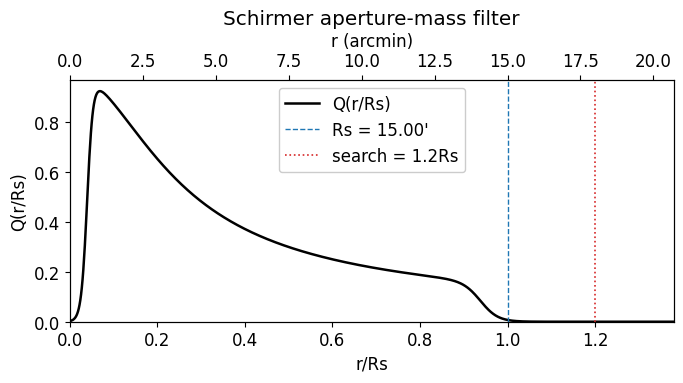

In [6]:
# Filter profile vs r/Rs, with Rs and the aperture search radius marked.
rs_arcmin = float(CONFIG["RS_ARCMIN"])
x_max = float(CONFIG["SEARCH_RADIUS_RS_MULT"]) * 1.15
x = np.linspace(1e-4, x_max, 800)
q = schirmer_weight(x * CONFIG["RS_DEG"], CONFIG["RS_DEG"])

fig_q, ax_q = plt.subplots(figsize=(7.0, 4.0))
ax_q.plot(x, q, "k-", lw=1.8, label=r"Q(r/Rs)")
ax_q.axvline(1.0, color="C0", ls="--", lw=1.0, label=fr"Rs = {rs_arcmin:.2f}'")
ax_q.axvline(
    CONFIG["SEARCH_RADIUS_RS_MULT"],
    color="C3",
    ls=":",
    lw=1.2,
    label=fr"search = {CONFIG['SEARCH_RADIUS_RS_MULT']}Rs",
)
ax_q.set_xlabel(r"r/Rs")
ax_q.set_ylabel(r"Q(r/Rs)")
ax_q.set_xlim(0, x_max)
ax_q.set_ylim(bottom=0)
ax_q.legend(framealpha=1)
ax_q.set_title("Schirmer aperture-mass filter")

ax_r = ax_q.twiny()
ax_r.set_xlim(0, x_max * rs_arcmin)
ax_r.set_xlabel(r"r (arcmin)")
fig_q.tight_layout()
save_plot(fig_q, "schirmer_filter")

In [7]:
def aperture_mass_and_sn_at_center(
    ra_c,
    dec_c,
    ra_all,
    dec_all,
    g1_all,
    g2_all,
    *,
    theta_max_arcmin,
    rs_deg,
    w_all=None,
    xc=None,
    g1_rand=None,
    g2_rand=None,
):
    """Filtered aperture E- and B-mode statistics and S/N at one center; optional w_all weights galaxies.

    Returns (ap_e, sn_e, ap_b, sn_b, sn_rand). sn_rand holds the E-mode S/N for each random-rotation
    realization, from g1_rand/g2_rand (shape n_gal x K), or is None when those are not given. A
    realization rotates every galaxy by a fixed random angle (the same angle in every aperture), which
    removes the lensing signal and keeps the shape noise and source positions.
    """
    nan5 = (np.nan, np.nan, np.nan, np.nan, None)
    theta_max_deg = float(theta_max_arcmin) / 60.0
    dra = wrap_dra(ra_all, ra_c)  # Wrapped so apertures near RA = 0 keep sources across the seam
    ddec = dec_all - dec_c

    # Same tangent-plane metric as gamma_tx_sky (dx = dra * cos dec0) so Q(r) matches angular r.
    cos_dec0 = np.cos(np.deg2rad(dec_c))
    dtheta = np.hypot(dra * cos_dec0, ddec)

    # Restrict to sources inside the aperture; the KD-tree pre-selection is a superset of this.
    m = dtheta <= theta_max_deg
    if not np.any(m):
        return nan5

    ra_s = ra_all[m]
    dec_s = dec_all[m]
    g1_s = g1_all[m]
    g2_s = g2_all[m]
    d_theta = dtheta[m]
    n_g = int(ra_s.size)

    # Uniform weights unless per-object inverse variances are supplied.
    w_s = np.ones(n_g, dtype=np.float64) if w_all is None else np.asarray(w_all, dtype=np.float64)[m]

    gt, gx = gamma_tx_sky(ra_s, dec_s, g1_s, g2_s, center=(ra_c, dec_c))

    Qi = schirmer_weight(d_theta, rs_deg, xc)
    w_sum = float(np.sum(w_s))
    if w_sum <= 0.0 or not np.isfinite(w_sum):
        return nan5

    # Weighted aperture statistics: E-mode from g_t, B-mode from g_x.
    ap_e = np.sum(Qi * gt * w_s) / w_sum
    ap_b = np.sum(Qi * gx * w_s) / w_sum

    # Shape-noise error estimate, sum_i Q_i^2 |e_i|^2 w_i^2, giving S/N = sqrt(2) * signal / noise.
    denom = np.sqrt(np.sum((Qi**2) * (g1_s**2 + g2_s**2) * (w_s**2)))
    if denom <= 0.0 or not np.isfinite(denom):
        return ap_e, np.nan, ap_b, np.nan, None
    sn_e = np.sqrt(2.0) * (w_sum * ap_e) / denom
    sn_b = np.sqrt(2.0) * (w_sum * ap_b) / denom

    sn_rand = None
    if g1_rand is not None:
        # |g| is unchanged by rotation, so the noise denominator is shared by all realizations.
        phi = np.arctan2(dec_s - dec_c, dra[m] * cos_dec0)
        c2, s2 = np.cos(2.0 * phi)[:, None], np.sin(2.0 * phi)[:, None]
        gt_r = -(g1_rand[m] * c2 + g2_rand[m] * s2)
        sn_rand = np.sqrt(2.0) * ((Qi * w_s) @ gt_r) / denom
    return ap_e, sn_e, ap_b, sn_b, sn_rand

In [8]:
def find_peaks_shear_healpix(
    ipix_eval,
    sn_map,
    completeness,
    nside,
    excl_radius_arcmin,
    sn_min=None,
    completeness_min=0.8,
):
    """Peaks of an S/N map on HEALPix cells.

    A cell is a peak if (1) its S/N is the highest among all evaluated cells within excl_radius_arcmin,
    (2) its aperture completeness is at least completeness_min, and (3) its S/N is at least sn_min.
    Using S/N rather than M_ap means a noisy shallow region does not produce large-|M_ap| peaks. An
    exclusion radius of about the noise decorrelation length (~0.4 Rs) stops one noise bump from
    being counted several times. Returns the HEALPix indices of the peaks, highest S/N first.
    """
    ipix_eval = np.asarray(ipix_eval, dtype=np.int64)
    sn_map = np.asarray(sn_map, dtype=np.float64)
    completeness = np.asarray(completeness, dtype=np.float64)

    # ipix_eval is sorted (np.unique), so HEALPix index -> array position is a searchsorted lookup.
    srt = np.argsort(ipix_eval)
    ip_sorted = ipix_eval[srt]

    cand = np.isfinite(sn_map) & (completeness >= completeness_min)
    if sn_min is not None:
        cand &= sn_map >= sn_min
    order = np.flatnonzero(cand)
    order = order[np.argsort(-sn_map[order])]

    excl_rad = np.deg2rad(float(excl_radius_arcmin) / 60.0)
    peaks = []
    for k in order:
        vec = hp.pix2vec(nside, int(ipix_eval[k]), nest=False)
        disc = hp.query_disc(nside, vec, excl_rad, inclusive=False, nest=False)
        pos = np.clip(np.searchsorted(ip_sorted, disc), 0, ip_sorted.size - 1)
        j = srt[pos[ip_sorted[pos] == disc]]
        vals = sn_map[j]
        if np.all(~np.isfinite(vals) | (vals <= sn_map[k]) | (j == k)):
            peaks.append(int(ipix_eval[k]))
    return np.asarray(peaks, dtype=np.int64)

## 2.0 Load data

In [9]:
theta_max_deg = CONFIG["THETA_MAX_ARCMIN"] / 60.0
NEIGHBOR_TRACTS, TRACT_BUFFER_CIRCLE = [], None

if USE_BUTLER:
    object_columns = resolve_object_columns(butler, CONFIG["TRACT"])
    available_tracts = object_tract_ids(butler)
    skymap = butler.get("skyMap", dataId={"skymap": CONFIG["SKYMAP"]})

    # The cluster must lie in the target tract for the map to cover it.
    _cluster_tract = skymap.findTract(SpherePoint(CLUSTER["ra"], CLUSTER["dec"], degrees)).getId()
    print(f"{CLUSTER['name']} lies in tract {_cluster_tract}")
    assert _cluster_tract == CONFIG["TRACT"], "set CONFIG['TRACT'] to the cluster tract"

    try:
        NEIGHBOR_TRACTS, TRACT_BUFFER_CIRCLE = neighbor_tract_ids(
            skymap, CONFIG["TRACT"], available_tracts, theta_max_deg
        )
    except Exception as exc:
        print("Neighbor lookup failed, mapping the target tract only:", exc)

    data = load_object_table(butler, CONFIG["TRACT"], object_columns)
else:
    skymap = None
    data = Table.read(CONFIG["LOCAL_TABLE"])
    object_columns = [c for c in OBJECT_COLUMNS if c in data.colnames]

print(f"Target tract {CONFIG['TRACT']}: {len(data):,} rows")
print("Neighbor tracts:", NEIGHBOR_TRACTS or "none")

Target tract 2877: 782,475 rows
Neighbor tracts: none


## 3.0 Source selection

The cuts follow selection_cuts.md, which is written for the metadetect catalog
(object_shear_all). Here we use the object table and HSM regauss shapes, so each cut
is applied through its object-table counterpart:

| selection_cuts.md (metadetect) | Used here (object table) |
| --- | --- |
| all *_flags false | i-band measurement, PSF, shape, GAaP, and Sersic flags |
| bmask_flags, image_flags, mfrac < 0.1 | i-band pixelFlags_* (bad, nodata, edge, saturatedCenter, crCenter, interpolatedCenter, suspectCenter) |
| is_primary | detect_isDeblendedModelSource |
| SNR > 10 | griz Sersic flux S/N > SNR_MIN (set in CONFIG) |
| reso_factor > 0.5 | 1 - T_PSF/T_obj from the i-band second moments, > RESO_FACTOR_MIN (set in CONFIG) |
| \|g-r\|, \|r-i\|, \|i-z\| < 5 | same, on AB magnitudes from the Sersic fluxes |
| gauss_T < 20 | optional cut on i_ixx + i_iyy, disabled by default |

There is no per-object masked-pixel fraction in the object table, so mfrac is covered only
indirectly by the pixel flags. Two cuts specific to this analysis are added on top: a bound on
the HSM distortion, and a red-sequence veto.

All color cuts use magnitudes corrected for Milky Way dust, $m_0 = m - R_{\rm band}\,E(B-V)$, following Rubin
tutorial 311.1. E(B−V) is the Object-table `ebv` column (SFD98 at each object's position) and R_band comes from
rubin_sim `DustValues().r_x` (CCM89, R_V = 3.1, flat SED): R_g, R_r, R_i, R_z = 3.661, 2.701, 2.054, 1.590.
Without the correction, reddening moves red-sequence galaxies below the veto line by about
(R_g − R_i) − 2.0484 (R_r − R_z) ≈ −0.67 E(B−V) mag in g−i, so they leak into the source sample in dusty tracts.
Set `CONFIG["DEREDDEN"] = False` to turn the correction off.

### 3.1 Per-object quantities

In [10]:
# Sersic fluxes and their errors, in nJy.
g_flux, g_err = _col(data, "g_sersicFlux"), _col(data, "g_sersicFluxErr")
r_flux, r_err = _col(data, "r_sersicFlux"), _col(data, "r_sersicFluxErr")
i_flux, i_err = _col(data, "i_sersicFlux"), _col(data, "i_sersicFluxErr")
z_flux, z_err = _col(data, "z_sersicFlux"), _col(data, "z_sersicFluxErr")

# AB magnitudes, dust-corrected when CONFIG["DEREDDEN"]; non-positive fluxes become NaN and are dropped by the
# color cuts below.
_mags = griz_mags(data)
g_mag, r_mag, i_mag, z_mag = (_mags[b] for b in "griz")
if CONFIG["DEREDDEN"]:
    _ebv = _col(data, CONFIG["EBV_COLUMN"])
    print(
        f"E(B-V) in tract {CONFIG['TRACT']}: median {np.nanmedian(_ebv):.3f}, "
        f"range {np.nanmin(_ebv):.3f} to {np.nanmax(_ebv):.3f}"
    )
    print("A_band at the median:", {b: round(CONFIG['EXTINCTION_R'][b] * float(np.nanmedian(_ebv)), 3) for b in 'griz'})

# Adjacent-band colors for the sanity cuts, plus (g-i, r-z) for the red-sequence line.
gr = g_mag - r_mag
ri = r_mag - i_mag
iz = i_mag - z_mag
gi = g_mag - i_mag
rz = r_mag - z_mag

# Per-band detection significance.
g_snr = g_flux / g_err
r_snr = r_flux / r_err
i_snr = i_flux / i_err
z_snr = z_flux / z_err

# Resolution factor: 1 - (PSF second moments) / (object second moments).
# Values near 0 are PSF-like, so stars sit near the bottom of the diagnostic below.
reso_factor = 1 - (_col(data, "i_ixxPSF") + _col(data, "i_iyyPSF")) / (
    _col(data, "i_ixx") + _col(data, "i_iyy")
)

### 3.2 Diagnostics

Color-color and star-galaxy separation planes, with the cut thresholds drawn on top.

(-1.0, 3.0)

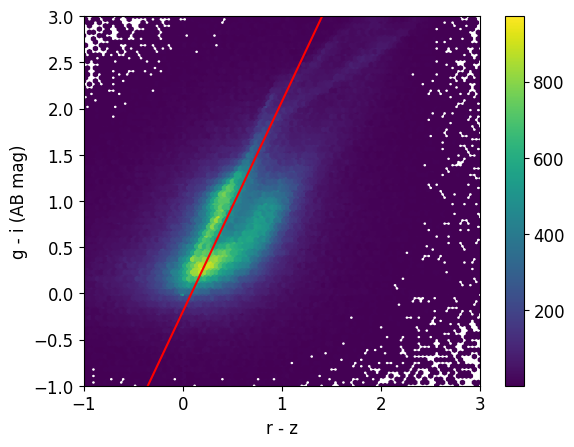

In [11]:
# Color-color plane before any cuts, with the red-sequence veto line from CONFIG.
_cc_tag = ", dereddened" if CONFIG["DEREDDEN"] else ""

def cc_seq_parallel(rz):
    return CONFIG["RED_SEQ_SLOPE"] * rz + CONFIG["RED_SEQ_INTERCEPT"]

plt.hexbin(rz, gi, mincnt=1, extent=(-1,3,-1,3))
s = np.linspace(-5,5, 1000)
plt.plot(s, cc_seq_parallel(s), "r-")
plt.ylabel(f"g - i (AB mag{_cc_tag})")
plt.xlabel(f"r - z (AB mag{_cc_tag})")
plt.colorbar()
plt.xlim(-1,3)
plt.ylim(-1,3)

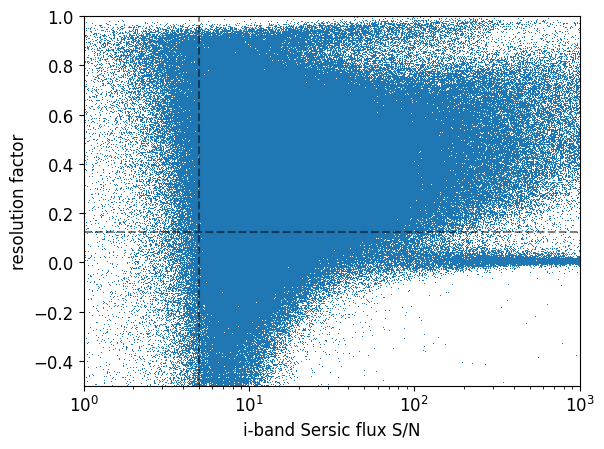

In [12]:
# Star-galaxy separation plane; the dashed lines mark the cuts applied in 3.3.
plt.plot(i_snr, reso_factor, ',')
plt.axhline(CONFIG["RESO_FACTOR_MIN"], ls='--', color='k', alpha=0.5)
plt.axvline(CONFIG["SNR_MIN"], ls='--', color='k', alpha=0.5)
plt.xlabel("i-band Sersic flux S/N")
plt.ylabel("resolution factor")
plt.ylim(-0.5, 1.0)
plt.xlim(1, 1000)
plt.semilogx()
save_plot(plt.gcf(), f"{CONFIG['TRACT']}_star_galaxy")

### 3.3 Apply the cuts

The red-sequence veto removes galaxies above a line of slope 2.0484 (intercept −0.10) in the dereddened (r−z, g−i) plane. These are likely
cluster members rather than lensed background sources, so they would dilute the signal.

In [13]:
mask, groups = selection_mask(data)
shear_catalog = data[mask]
from_target = np.ones(len(shear_catalog), dtype=bool)

for _name, _cut in groups.items():
    print(f"{_name:<28} {int(np.sum(_cut)):>10,}")
print(f"{'all cuts':<28} {len(shear_catalog):>10,} of {len(data):,}")

measurement + pixel flags       507,297
deblended model source          681,757
|e| <= 2                        546,562
reso_factor > 0.125             559,231
extendedness + S/N > 5          399,090
colors + red sequence           401,241
size                            782,475
all cuts                        163,302 of 782,475


In [14]:
# Source density over the tract's unique (inner) area. Without the skymap, the area is the
# footprint of occupied NSIDE=1024 (3.4') cells, which slightly overestimates the area at the edges.
if skymap is not None:
    tract_area = tract_area_deg2(skymap, CONFIG["TRACT"])
else:
    _ip = hp.ang2pix(1024, _col(shear_catalog, "coord_ra"), _col(shear_catalog, "coord_dec"), lonlat=True)
    tract_area = np.unique(_ip).size * hp.nside2pixarea(1024, degrees=True)
print(f"tract area: {tract_area:.3f} deg^2")
N_DENSITY = len(shear_catalog) / (tract_area * 3600.0)  # gal / arcmin^2, used for aperture completeness
print(round(N_DENSITY, 3), "gal / arcmin^2")

tract area: 2.420 deg^2
18.748 gal / arcmin^2


(-1.0, 3.0)

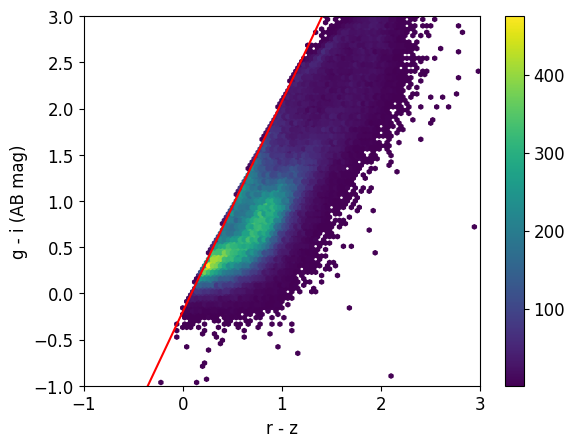

In [15]:
# Same color-color plane after the cuts: the red sequence should be removed.
_mags_sel = griz_mags(shear_catalog)  # same (dust-corrected) magnitudes as the cuts
plt.hexbin(
    _mags_sel["r"] - _mags_sel["z"],
    _mags_sel["g"] - _mags_sel["i"], mincnt=1, extent=(-1,3,-1,3))
s = np.linspace(-5,5, 1000)
plt.plot(s, cc_seq_parallel(s), "r-")
plt.ylabel(f"g - i (AB mag{_cc_tag})")
plt.xlabel(f"r - z (AB mag{_cc_tag})")
plt.colorbar()
plt.xlim(-1,3)
plt.ylim(-1,3)

Number of selected galaxies per HEALPix cell after the cuts.

Occupied cells: 10,871  |  galaxies/cell: min=1  median=15  mean=15.0  max=39


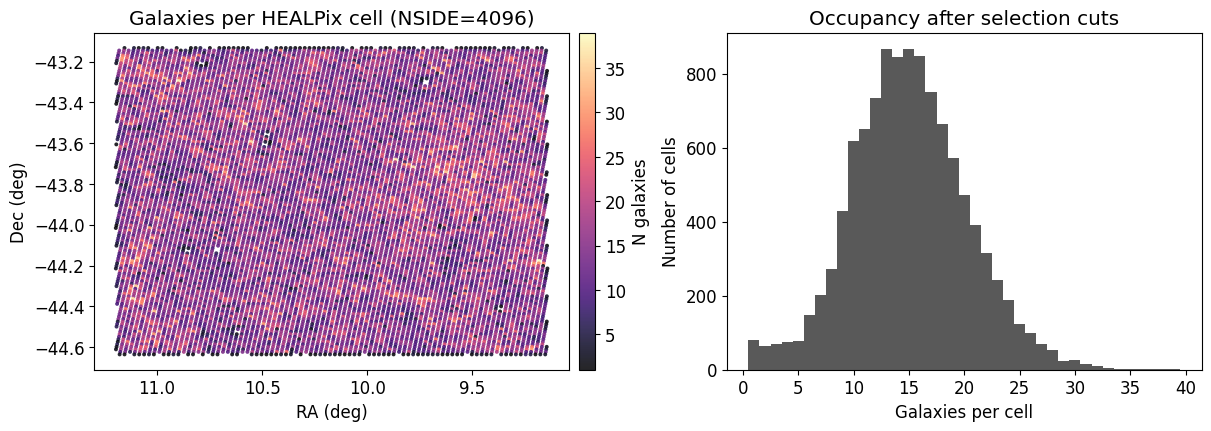

In [16]:
# Occupied HEALPix cells after the selection cuts (target tract only).
nside_gal = int(CONFIG["NSIDE"])
ra_sel = _col(shear_catalog, "coord_ra")
dec_sel = _col(shear_catalog, "coord_dec")
ipix_sel = hp.ang2pix(nside_gal, ra_sel, dec_sel, nest=False, lonlat=True)
ipix_occ, n_gal_cell = np.unique(ipix_sel, return_counts=True)
ra_cell, dec_cell = hp.pix2ang(nside_gal, ipix_occ, nest=False, lonlat=True)

print(
    f"Occupied cells: {ipix_occ.size:,}  |  "
    f"galaxies/cell: min={int(n_gal_cell.min())}  "
    f"median={np.median(n_gal_cell):.0f}  "
    f"mean={n_gal_cell.mean():.1f}  "
    f"max={int(n_gal_cell.max())}"
)

fig_ngal, axes_ngal = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
pt_ngal = max(1.0, min(8.0, 500_000.0 / max(int(ipix_occ.size), 1)))
sc_ngal = axes_ngal[0].scatter(
    ra_cell,
    dec_cell,
    c=n_gal_cell,
    s=pt_ngal,
    cmap="magma",
    linewidths=0,
    alpha=0.85,
)
axes_ngal[0].set_xlabel("RA (deg)")
axes_ngal[0].set_ylabel("Dec (deg)")
axes_ngal[0].set_title(f"Galaxies per HEALPix cell (NSIDE={nside_gal})")
axes_ngal[0].invert_xaxis()
fig_ngal.colorbar(sc_ngal, ax=axes_ngal[0], fraction=0.046, pad=0.02, label="N galaxies")

n_max = int(n_gal_cell.max())
bins_ngal = np.arange(0.5, n_max + 1.5, 1) if n_max < 80 else 40
axes_ngal[1].hist(n_gal_cell, bins=bins_ngal, histtype="stepfilled", color="0.35")
axes_ngal[1].set_xlabel("Galaxies per cell")
axes_ngal[1].set_ylabel("Number of cells")
axes_ngal[1].set_title("Occupancy after selection cuts")
save_plot(fig_ngal, f"{CONFIG['TRACT']}_ngal_cells")

### 3.4 Neighbor-tract buffer

Selected galaxies from neighboring tracts within the search radius of the target tract.

In [17]:
n_target = len(shear_catalog)
pieces = [shear_subset(shear_catalog)]
del shear_catalog, data
gc.collect()

for tid in NEIGHBOR_TRACTS:  # empty in local-table mode
    try:
        tbl = load_object_table(butler, tid, object_columns)
    except Exception as exc:
        print(f"tract {tid}: skipped ({exc})")
        continue
    nb_mask, _ = selection_mask(tbl)
    sel = shear_subset(tbl[nb_mask])
    del tbl
    if len(sel) == 0:
        gc.collect()
        continue
    keep = in_circle(sel["coord_ra"], sel["coord_dec"], TRACT_BUFFER_CIRCLE)
    n_keep = int(np.sum(keep))
    if n_keep:
        pieces.append(sel[keep])
    del sel
    gc.collect()
    print(f"tract {tid}: {n_keep:,} galaxies in buffer")

shear_catalog = vstack(pieces, join_type="inner") if len(pieces) > 1 else pieces[0]
del pieces
gc.collect()

shear_catalog, from_target = dedupe_objectid(shear_catalog, n_target)
print(
    f"Shear catalog: {int(from_target.sum()):,} in tract, "
    f"{int((~from_target).sum()):,} from neighbors "
    f"({len(shear_catalog):,} unique)"
)

Shear catalog: 163,302 in tract, 0 from neighbors (163,302 unique)


## 4.0 Map on HEALPix

### 4.1 Shear calibration, frame, and weights

Regauss distortions are converted to shear with the responsivity R and multiplicative bias
m calibrated on Abell 360: $g = e / [2R(1+m)]$.

**Shear frame (E2_SIGN = −1).** `i_hsmShapeRegauss_e1/e2` are measured from pixel moments on the coadd, whose pixel x axis
points toward decreasing RA. Positions in `gamma_tx_sky` are projected with x toward increasing RA (east) and y toward
increasing Dec. The two frames are mirror images in x. A reflection leaves $e_1 \propto I_{xx}-I_{yy}$ unchanged and flips the
sign of $e_2 \propto I_{xy}$, so we set $e_2 \to -e_2$ before rotating to tangential and cross components. This is necessary:
with mixed frames a purely tangential field ($g_1 = -g_t\cos2\phi$, $g_2 = -g_t\sin2\phi$) is measured as $g_t\cos4\phi$ in the
E-mode and $g_t\sin4\phi$ in the B-mode. Both average to zero over azimuth, so the lensing signal would vanish from both maps.
The pixel axes match RA/Dec only near the tract center. At the cluster the residual rotation is about 0.03°, which is
negligible here. A survey-wide analysis should instead rotate each shape by the local WCS position angle.

**Weights.** $w = 1/(\sigma_{e,\rm int}^2 + \sigma_e^2)$, where $\sigma_e$ is `i_hsmShapeRegauss_sigma`, the per-component
distortion error. The intrinsic dispersion is estimated from the catalog as
$\sigma_{e,\rm int}^2 = \langle e_1^2+e_2^2\rangle/2 - {\rm median}(\sigma_e^2)$.

In [18]:
# Quick check that the mean ellipticity is small; a large value signals additive bias.
np.mean(shear_catalog['i_hsmShapeRegauss_e1'])

np.float64(0.0003768724536205471)

In [19]:
# Responsivity and multiplicative bias from the A360 calibration.
R, m_mean = 0.8511839657185559, -0.13584282915829576

ra_deg = _col(shear_catalog, "coord_ra")
dec_deg = _col(shear_catalog, "coord_dec")

# Distortion -> shear: g = e / (2R) / (1 + m), with e2 flipped from the pixel frame into the RA/Dec frame.
e1_0 = _col(shear_catalog, "i_hsmShapeRegauss_e1")
e2_0 = CONFIG["E2_SIGN"] * _col(shear_catalog, "i_hsmShapeRegauss_e2")
g1 = (e1_0 / (2.0 * R)) / (1.0 + m_mean)
g2 = (e2_0 / (2.0 * R)) / (1.0 + m_mean)

# Weights: 1 / (intrinsic distortion variance + measurement variance), both per component.
sig_e = _col(shear_catalog, "i_hsmShapeRegauss_sigma")
if CONFIG["SHAPE_NOISE_E"] is None:
    _s2 = np.nanmean(e1_0**2 + e2_0**2) / 2.0 - np.nanmedian(sig_e**2)
    CONFIG["SHAPE_NOISE_E"] = float(np.sqrt(max(_s2, 0.05)))
_var_sum = CONFIG["SHAPE_NOISE_E"] ** 2 + sig_e**2
with np.errstate(divide="ignore", invalid="ignore"):
    w_gal = np.where(np.isfinite(_var_sum) & (_var_sum > 0.0), 1.0 / _var_sum, 0.0)

# Effective source density and per-component shear dispersion.
N_EFF = N_DENSITY * np.sum(w_gal[from_target]) ** 2 / np.sum(w_gal[from_target] ** 2) / from_target.sum()
SIGMA_G = float(np.sqrt(np.sum(w_gal**2 * (g1**2 + g2**2) / 2) / np.sum(w_gal**2)))

print("N galaxies:", ra_deg.size)
print("Galaxies with positive finite weight:", int(np.sum(w_gal > 0)))
print(f"sigma_e,int (distortion, per component) = {CONFIG['SHAPE_NOISE_E']:.3f}")
print(f"n_eff = {N_EFF:.1f} / arcmin^2,  sigma_g (shear, per component, weighted) = {SIGMA_G:.3f}")

N galaxies: 163302
Galaxies with positive finite weight: 163302
sigma_e,int (distortion, per component) = 0.524
n_eff = 17.8 / arcmin^2,  sigma_g (shear, per component, weighted) = 0.344


In [ ]:
# Effective source density from the weights above (target-tract sources only).
_t = from_target & (w_gal > 0)
_w = w_gal[_t]
_area = tract_area * 3600.0  # arcmin^2
sig_int = CONFIG["SHAPE_NOISE_E"] / (2.0 * R * (1.0 + m_mean))  # intrinsic shape noise, shear per component

# Heymans+12: n_eff = (sum w)^2 / (A sum w^2), paired with the weighted shear dispersion.
n_eff_H = np.sum(_w) ** 2 / np.sum(_w**2) / _area
sig_H = np.sqrt(np.sum(_w**2 * (g1[_t] ** 2 + g2[_t] ** 2) / 2) / np.sum(_w**2))

# Chang+13: n_eff = sum_i sigma_int^2 / (sigma_int^2 + sigma_i^2) / A, paired with sigma_int.
n_eff_C = CONFIG["SHAPE_NOISE_E"] ** 2 * np.sum(_w) / _area

print(f"raw n = {_t.sum() / _area:.2f} / arcmin^2")
print(f"Heymans+12: n_eff = {n_eff_H:.2f} / arcmin^2, sigma = {sig_H:.3f}, sigma^2/n_eff = {sig_H**2 / n_eff_H:.2e} arcmin^2")
print(f"Chang+13:   n_eff = {n_eff_C:.2f} / arcmin^2, sigma = {sig_int:.3f}, sigma^2/n_eff = {sig_int**2 / n_eff_C:.2e} arcmin^2")
print(f"equivalent n at sigma = 0.25 (Frieman 2026): {0.25**2 * n_eff_H / sig_H**2:.2f} / arcmin^2")

### 4.2 Tangential shear profile around the cluster

Weighted mean $g_t$ and $g_\times$ in log-spaced annuli around the SZ position.

In [20]:
def tangential_profile(g1_, g2_, w_, center, bins_arcmin):
    """Weighted <g_t>, <g_x> and shape-noise errors in annuli about center (ra, dec)."""
    x = wrap_dra(ra_deg, center[0]) * np.cos(np.deg2rad(center[1])) * 60.0
    y = (dec_deg - center[1]) * 60.0
    r = np.hypot(x, y)
    gt_, gx_ = gamma_tx_sky(ra_deg, dec_deg, g1_, g2_, center)
    rc, mt, mx, err = [], [], [], []
    for lo, hi in zip(bins_arcmin[:-1], bins_arcmin[1:]):
        s = (r >= lo) & (r < hi)
        ws = w_[s]
        rc.append(np.sqrt(lo * hi))
        mt.append(np.sum(ws * gt_[s]) / ws.sum())
        mx.append(np.sum(ws * gx_[s]) / ws.sum())
        err.append(np.sqrt(np.sum(ws**2 * (g1_[s] ** 2 + g2_[s] ** 2) / 2)) / ws.sum())
    return np.array(rc), np.array(mt), np.array(mx), np.array(err)


PROFILE_BINS = np.geomspace(0.75, 25.0, 12)
prof = tangential_profile(g1, g2, w_gal, (CLUSTER["ra"], CLUSTER["dec"]), PROFILE_BINS)
rc, mt, mx, err = prof

fig_p, ax_p = plt.subplots(figsize=(7, 4.5))
ax_p.errorbar(rc, mt, err, fmt="o", color="C3", label=r"$g_t$")
ax_p.errorbar(rc * 1.05, mx, err, fmt="s", mfc="none", color="0.4", label=r"$g_\times$")
ax_p.axhline(0, color="k", lw=0.8)
ax_p.set_xscale("log")
ax_p.set_xlabel(f"θ from {CLUSTER['name']} (arcmin)")
ax_p.set_ylabel("shear")
ax_p.set_title("Tangential and cross shear profile")
ax_p.legend()
fig_p.tight_layout()
save_plot(fig_p, f"{CONFIG['TRACT']}_PSZ2_G309_tangential_profile")

### 4.3 Aperture statistic on every cell

`N_RANDOM` noise realizations are computed alongside the map. In each, every galaxy is rotated by a random angle that
stays fixed across apertures. These maps keep the real positions, weights, masks, and depth variations but contain no
lensing signal.

Aperture completeness is the number of sources within the search disc divided by `N_DENSITY · π θ_max²`. It is low
near tract edges when neighbors are missing, and around large masks.

In [21]:
def run_aperture_map(nside, rs_deg, theta_max_arcmin, xc=None, n_random=0, eval_mask=None, seed=0, progress=True):
    """Evaluate the aperture statistic on every occupied HEALPix cell of the target tract.

    Returns a dict with ipix, ap_e, sn_e, ap_b, sn_b, counts, completeness and sn_rand (n_cell x n_random).
    eval_mask optionally restricts the evaluated cells (boolean over the occupied cells).
    """
    theta_max_deg = theta_max_arcmin / 60.0
    ipix_all = hp.ang2pix(nside, ra_deg, dec_deg, nest=False, lonlat=True)
    ipix_ev = np.unique(ipix_all[from_target])
    if eval_mask is not None:
        ipix_ev = ipix_ev[eval_mask(ipix_ev)]
    n = int(ipix_ev.size)
    out = {k: np.full(n, np.nan) for k in ("ap_e", "sn_e", "ap_b", "sn_b")}
    out["counts"] = np.zeros(n, dtype=np.int32)
    out["sn_rand"] = np.full((n, n_random), np.nan)

    g1r = g2r = None
    if n_random:
        rng = np.random.default_rng(seed)
        ang = rng.uniform(0.0, np.pi, size=(ra_deg.size, n_random))
        c2, s2 = np.cos(2 * ang), np.sin(2 * ang)
        g1r = g1[:, None] * c2 - g2[:, None] * s2
        g2r = g1[:, None] * s2 + g2[:, None] * c2

    it = tqdm(enumerate(ipix_ev), total=n, desc="HEALPix cells") if progress else enumerate(ipix_ev)
    for k, ip in it:
        # Cell center, then all galaxies within the search radius of it.
        ra_c, dec_c = hp.pix2ang(nside, int(ip), nest=False, lonlat=True)
        # Unit-sphere KD-tree query: no RA = 0 seam, and a superset of the tangent-plane cut.
        idx = tree.query_ball_point(radec_to_xyz(ra_c, dec_c)[0], r=chord_radius(theta_max_deg))
        if not idx:
            continue
        idx = np.asarray(idx, dtype=np.int64)
        res = aperture_mass_and_sn_at_center(
            float(ra_c), float(dec_c), ra_deg[idx], dec_deg[idx], g1[idx], g2[idx],
            theta_max_arcmin=theta_max_arcmin, rs_deg=rs_deg, w_all=w_gal[idx], xc=xc,
            g1_rand=None if g1r is None else g1r[idx], g2_rand=None if g2r is None else g2r[idx],
        )
        out["ap_e"][k], out["sn_e"][k], out["ap_b"][k], out["sn_b"][k] = res[:4]
        if res[4] is not None:
            out["sn_rand"][k] = res[4]
        _d = np.hypot(wrap_dra(ra_deg[idx], ra_c) * np.cos(np.deg2rad(dec_c)), dec_deg[idx] - dec_c)
        out["counts"][k] = int(np.sum(_d <= theta_max_deg))
    out["ipix"] = ipix_ev
    out["completeness"] = out["counts"] / (N_DENSITY * np.pi * theta_max_arcmin**2)
    return out


# KD-tree on unit vectors (no RA = 0 seam); the exact angular cut is redone inside the aperture function.
tree = cKDTree(radec_to_xyz(ra_deg, dec_deg))

theta_max_arcmin = CONFIG["THETA_MAX_ARCMIN"]
rs_deg = float(CONFIG["RS_DEG"])
nside = int(CONFIG["NSIDE"])

amap = run_aperture_map(nside, rs_deg, theta_max_arcmin, n_random=CONFIG["N_RANDOM"], seed=CONFIG["RANDOM_SEED"])
ipix_eval = amap["ipix"]
ap_mass_map, sn_ratio_map = amap["ap_e"], amap["sn_e"]
ap_bmode_map, sn_bmode_map = amap["ap_b"], amap["sn_b"]
counts_map, completeness_map, sn_rand_map = amap["counts"], amap["completeness"], amap["sn_rand"]
n_cell = int(ipix_eval.size)

_good = completeness_map >= CONFIG["PEAK_COMPLETENESS_MIN"]
print("N HEALPix cells evaluated:", n_cell, f"({int(_good.sum())} with completeness >= {CONFIG['PEAK_COMPLETENESS_MIN']})")
print("Finite E-mode (aperture mass) cells:", int(np.isfinite(ap_mass_map).sum()))
print("Finite B-mode cells:", int(np.isfinite(ap_bmode_map).sum()))
print(f"std of S/N on complete cells:  E = {np.nanstd(sn_ratio_map[_good]):.2f}   B = {np.nanstd(sn_bmode_map[_good]):.2f}   "
      f"random rotations = {np.nanstd(sn_rand_map[_good]):.2f}")

HEALPix cells:   0%|          | 0/10871 [00:00<?, ?it/s]

HEALPix cells:   0%|          | 46/10871 [00:00<00:23, 457.36it/s]

HEALPix cells:   1%|          | 94/10871 [00:00<00:23, 468.28it/s]

HEALPix cells:   1%|▏         | 141/10871 [00:00<00:24, 436.92it/s]

HEALPix cells:   2%|▏         | 189/10871 [00:00<00:23, 450.03it/s]

...

HEALPix cells:  99%|█████████▉| 10775/10871 [00:49<00:00, 411.65it/s]

HEALPix cells: 100%|█████████▉| 10824/10871 [00:49<00:00, 432.60it/s]

HEALPix cells: 100%|█████████▉| 10868/10871 [00:49<00:00, 432.53it/s]

HEALPix cells: 100%|██████████| 10871/10871 [00:49<00:00, 219.64it/s]

N HEALPix cells evaluated: 10871 (7517 with completeness >= 0.8)
Finite E-mode (aperture mass) cells: 10871
Finite B-mode cells: 10871
std of S/N on complete cells:  E = 1.39   B = 1.04   random rotations = 1.01


### 4.4 Save the map

In [22]:
# Sky coordinates of the evaluated cell centers.
ra_pix, dec_pix = hp.pix2ang(nside, ipix_eval, nest=False, lonlat=True)
ra_pix = np.asarray(ra_pix, dtype=np.float64)
dec_pix = np.asarray(dec_pix, dtype=np.float64)

In [23]:
aper = Table(
    data=[ra_pix, dec_pix, ap_mass_map, ap_bmode_map, sn_ratio_map, sn_bmode_map, completeness_map],
    names=["RA", "DEC", "E_ap", "B_ap", "E_SN", "B_SN", "COMPLETENESS"],
)
aper.meta.update({"RS_ARCMIN": CONFIG["RS_ARCMIN"], "FILTER_XC": CONFIG["FILTER_XC"], "NSIDE": nside, "E2_SIGN": CONFIG["E2_SIGN"], "DEREDDEN": CONFIG["DEREDDEN"]})
aper.write(OUTPUT_DIR / f"{CONFIG['TRACT']}_shapeHSM_massmap.fits", format="fits", overwrite=True)

## 5.0 Peaks

A peak is a cell whose E-mode S/N is the highest of all evaluated cells within `PEAK_EXCL_RS_MULT · Rs`, whose aperture
is at least `PEAK_COMPLETENESS_MIN` complete, and whose S/N is at least `PEAK_SN_MIN`. The threshold is chosen to sit
above the highest noise peak found in the random-rotation maps. Those maps include shape noise only. Cosmic shear adds
about 20% to the map scatter at Rs = 15′ (section 7).

In [24]:
sn_min = CONFIG.get("PEAK_SN_MIN")
excl_arcmin = CONFIG["PEAK_EXCL_RS_MULT"] * CONFIG["RS_ARCMIN"]
peak_kw = dict(nside=nside, excl_radius_arcmin=excl_arcmin, completeness_min=CONFIG["PEAK_COMPLETENESS_MIN"])

peak_ipix = find_peaks_shear_healpix(ipix_eval, sn_ratio_map, completeness_map, sn_min=sn_min, **peak_kw)
print("N peaks (with current cuts):", int(peak_ipix.size))

# Noise peaks in each random-rotation realization (no threshold), for the false-detection rate.
area_good = float(np.sum(completeness_map >= CONFIG["PEAK_COMPLETENESS_MIN"])) * hp.nside2pixarea(nside, degrees=True)
_idx_of = {int(p): k for k, p in enumerate(ipix_eval)}
rand_max, rand_n_above = [], []
for j in range(sn_rand_map.shape[1]):
    pk_r = find_peaks_shear_healpix(ipix_eval, sn_rand_map[:, j], completeness_map, sn_min=None, **peak_kw)
    vals = sn_rand_map[[_idx_of[int(p)] for p in pk_r], j]
    rand_max.append(np.nanmax(vals))
    rand_n_above.append(int(np.sum(vals >= (sn_min or 0))))
rand_max = np.asarray(rand_max)
print(f"Noise-only maps ({sn_rand_map.shape[1]} realizations, {area_good:.2f} deg^2 complete):")
print(f"  highest noise peak per tract: mean {rand_max.mean():.2f}, max {rand_max.max():.2f}")
print(f"  false peaks with S/N >= {sn_min}: {np.mean(rand_n_above):.2f} per tract = {np.mean(rand_n_above) / area_good:.2f} per deg^2")

_order = np.argsort(-sn_ratio_map[[_idx_of[int(p)] for p in peak_ipix]]) if peak_ipix.size else []
for p in peak_ipix:
    k = _idx_of[int(p)]
    _ra, _dec = hp.pix2ang(nside, int(p), lonlat=True)
    _sep = np.hypot(wrap_dra(_ra, CLUSTER["ra"]) * np.cos(np.deg2rad(CLUSTER["dec"])), _dec - CLUSTER["dec"]) * 60
    print(f"  peak RA={_ra:.4f} Dec={_dec:.4f}  S/N_E={sn_ratio_map[k]:.2f}  S/N_B={sn_bmode_map[k]:.2f}  "
          f"completeness={completeness_map[k]:.2f}  {_sep:.1f}' from {CLUSTER['name']}")

N peaks (with current cuts): 3


Noise-only maps (10 realizations, 1.54 deg^2 complete):
  highest noise peak per tract: mean 3.38, max 3.73
  false peaks with S/N >= 4.0: 0.00 per tract = 0.00 per deg^2
  peak RA=10.2084 Dec=-44.1271  S/N_E=7.71  S/N_B=2.13  completeness=1.08  0.2' from PSZ2 G309.43-72.86
  peak RA=10.2615 Dec=-44.4865  S/N_E=7.11  S/N_B=0.41  completeness=0.85  21.5' from PSZ2 G309.43-72.86
  peak RA=10.2730 Dec=-43.7797  S/N_E=4.13  S/N_B=0.46  completeness=1.07  21.2' from PSZ2 G309.43-72.86


## 6.0 Figures

### 6.1 Plot setup

In [25]:
# Recompute the cell centers so the figures can be run without the save step.
ra_pix, dec_pix = hp.pix2ang(nside, ipix_eval, nest=False, lonlat=True)
ra_pix = np.asarray(ra_pix, dtype=np.float64)
dec_pix = np.asarray(dec_pix, dtype=np.float64)

# Only plot cells with at least one galaxy in the aperture.
msk = counts_map > 0
if msk.any():
    m_lo, m_hi = np.nanpercentile(ap_mass_map[msk], [5, 95])
    sn_lo, sn_hi = np.nanpercentile(sn_ratio_map[msk], [5, 95])
    b_lo, b_hi = np.nanpercentile(ap_bmode_map[msk], [5, 95])
    snb_lo, snb_hi = np.nanpercentile(sn_bmode_map[msk], [5, 95])
else:
    m_lo = m_hi = sn_lo = sn_hi = b_lo = b_hi = snb_lo = snb_hi = None

# Marker size shrinks as the number of plotted cells grows.
pt_size = max(1.0, min(8.0, 500_000.0 / max(int(ipix_eval.size), 1)))

# gnomview needs a full-sky array, so skip it if that would be too large.
MAX_DENSE_NPIX = 4_000_000
_npix_hp = hp.nside2npix(nside)
do_gnomonic = _npix_hp <= MAX_DENSE_NPIX
if do_gnomonic:
    # Center the projection on the data.
    rot_ra = float(np.median(ra_pix))
    rot_dec = float(np.median(dec_pix))

    # Scatter the E-mode S/N onto the full sky, marking empty pixels as UNSEEN.
    sn_dense = np.full(_npix_hp, np.nan, dtype=np.float64)
    sn_dense[ipix_eval] = sn_ratio_map
    hp_sm = np.copy(sn_dense)
    hp_sm[~np.isfinite(hp_sm)] = hp.UNSEEN

    # Same for the B-mode S/N.
    snb_dense = np.full(_npix_hp, np.nan, dtype=np.float64)
    snb_dense[ipix_eval] = sn_bmode_map
    hp_smb = np.copy(snb_dense)
    hp_smb[~np.isfinite(hp_smb)] = hp.UNSEEN
else:
    hp_sm = hp_smb = None

### 6.2 E-mode maps

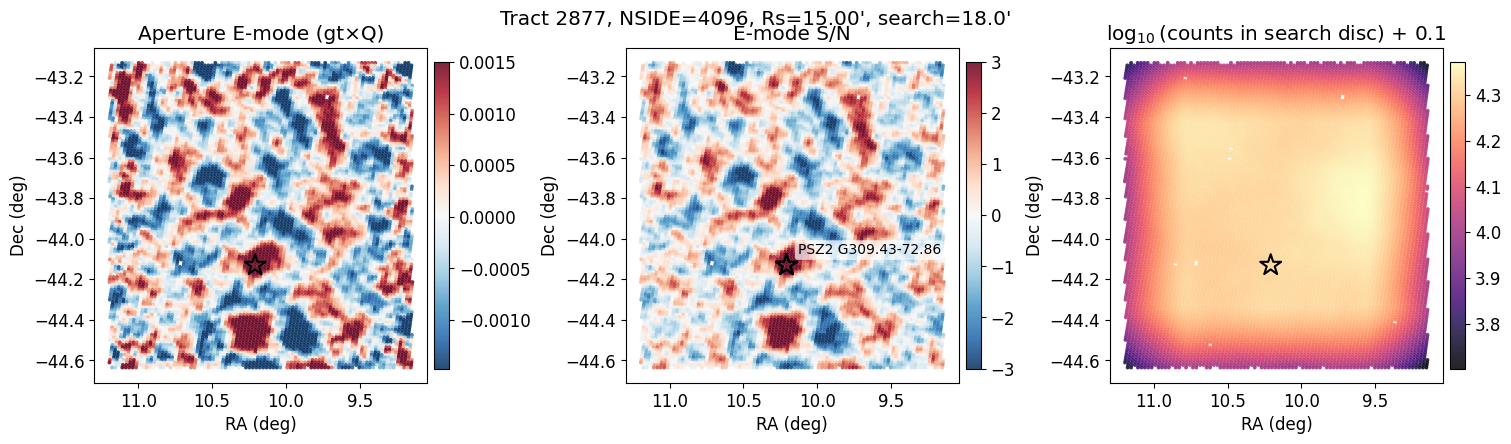

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

# Left: aperture E-mode signal.
sc0 = axes[0].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=ap_mass_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=m_lo,
    vmax=m_hi,
    linewidths=0,
    alpha=0.85,
)
axes[0].set_xlabel("RA (deg)")
axes[0].set_ylabel("Dec (deg)")
axes[0].set_title(r"Aperture E-mode (gt×Q)")
axes[0].invert_xaxis()  # RA increases to the left
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.02)

# Middle: the same quantity divided by its shape-noise error.
sc1 = axes[1].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_ratio_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-3.0,
    vmax=3.0,
    linewidths=0,
    alpha=0.85,
)
axes[1].set_xlabel("RA (deg)")
axes[1].set_ylabel("Dec (deg)")
axes[1].set_title(r"E-mode S/N")
axes[1].invert_xaxis()
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.02)

# Right: source density per aperture, offset before the log to keep empty cells finite.
logc = np.log10(counts_map.astype(np.float64) + 0.1)
sc2 = axes[2].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=logc[msk],
    s=pt_size,
    cmap="magma",
    linewidths=0,
    alpha=0.85,
)
axes[2].set_xlabel("RA (deg)")
axes[2].set_ylabel("Dec (deg)")
axes[2].set_title(r"$\log_{10}$(counts in search disc) + 0.1")
axes[2].invert_xaxis()
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.02)

for _ax in axes:
    mark_cluster(_ax, label=False)
mark_cluster(axes[1])

fig.suptitle(
    f"Tract {CONFIG['TRACT']}, NSIDE={nside}, Rs={CONFIG['RS_ARCMIN']:.2f}', search={theta_max_arcmin:.1f}'",
    y=1.02,
)
save_plot(fig, f"{CONFIG['TRACT']}_E-mode_map")

### 6.3 B-mode maps

Structure here at the level of the E-mode maps would indicate systematics rather than lensing.

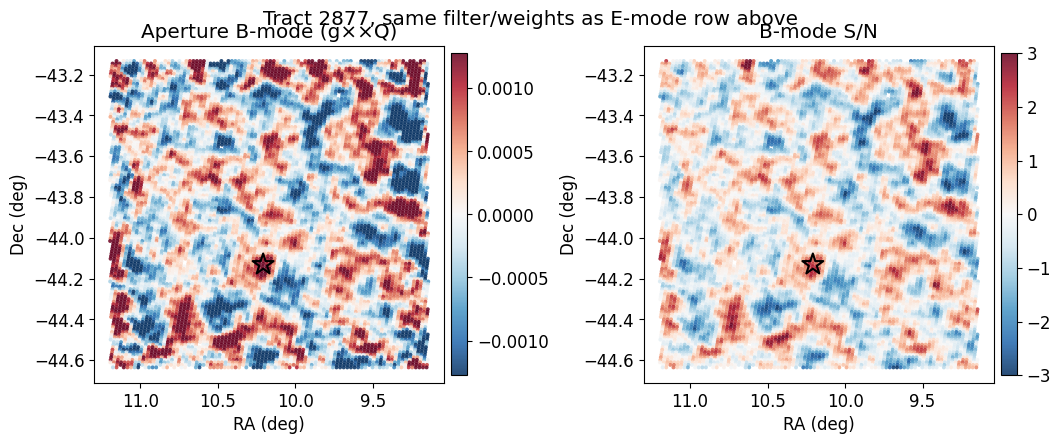

In [27]:
fig_eb, axes_eb = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)

# Left: aperture B-mode signal.
scb0 = axes_eb[0].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=ap_bmode_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=b_lo,
    vmax=b_hi,
    linewidths=0,
    alpha=0.85,
)
axes_eb[0].set_xlabel("RA (deg)")
axes_eb[0].set_ylabel("Dec (deg)")
axes_eb[0].set_title(r"Aperture B-mode (g××Q)")
axes_eb[0].invert_xaxis()
fig_eb.colorbar(scb0, ax=axes_eb[0], fraction=0.046, pad=0.02)

# Right: B-mode S/N.
scb1 = axes_eb[1].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_bmode_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-3.0,
    vmax=3.0,
    linewidths=0,
    alpha=0.85,
)
axes_eb[1].set_xlabel("RA (deg)")
axes_eb[1].set_ylabel("Dec (deg)")
axes_eb[1].set_title(r"B-mode S/N")
axes_eb[1].invert_xaxis()
fig_eb.colorbar(scb1, ax=axes_eb[1], fraction=0.046, pad=0.02)

for _ax in axes_eb:
    mark_cluster(_ax, label=False)

fig_eb.suptitle(
    f"Tract {CONFIG['TRACT']}, same filter/weights as E-mode row above",
    y=1.02,
)
save_plot(fig_eb, f"{CONFIG['TRACT']}_B-mode_map")

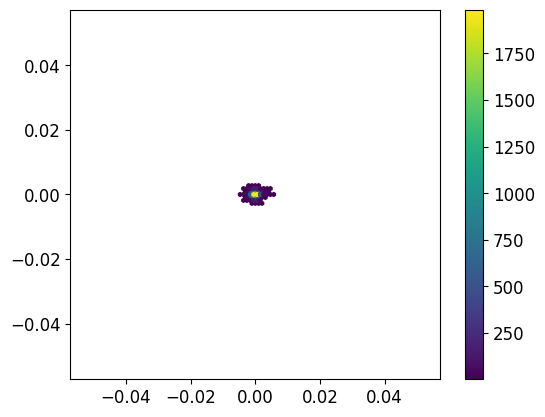

In [28]:
# E-mode against B-mode aperture values per occupied cell.
plt.hexbin(ap_mass_map[msk], ap_bmode_map[msk], mincnt=1)
plt.colorbar()
plt.gca().set_aspect(1)
save_plot(plt.gcf(), f"{CONFIG['TRACT']}_EB_hexbin")

In [ ]:
# Histogram of E-mode and B-mode aperture values per occupied cell.
# B should look like pure noise; an E-mode tail beyond it is the lensing signal.
e_vals = ap_mass_map[msk]
b_vals = ap_bmode_map[msk]
e_vals = e_vals[np.isfinite(e_vals)]
b_vals = b_vals[np.isfinite(b_vals)]
eb_bins = np.histogram_bin_edges(np.concatenate([e_vals, b_vals]), bins=60)

fig_hist, ax_hist = plt.subplots(figsize=(6, 4.2), constrained_layout=True)
ax_hist.hist(e_vals, bins=eb_bins, histtype="step", linewidth=1.5, label="E-mode")
ax_hist.hist(b_vals, bins=eb_bins, histtype="step", linewidth=1.5, label="B-mode")
ax_hist.set_xlabel("Aperture mass")
ax_hist.set_ylabel("Number of cells")
ax_hist.legend()
save_plot(fig_hist, f"{CONFIG['TRACT']}_EB_hist")

### 6.4 Peaks against PSZ2 G309.43-72.86

[10.2084399  10.26153053 10.27298121] [-44.12712892 -44.48654488 -43.77965341]


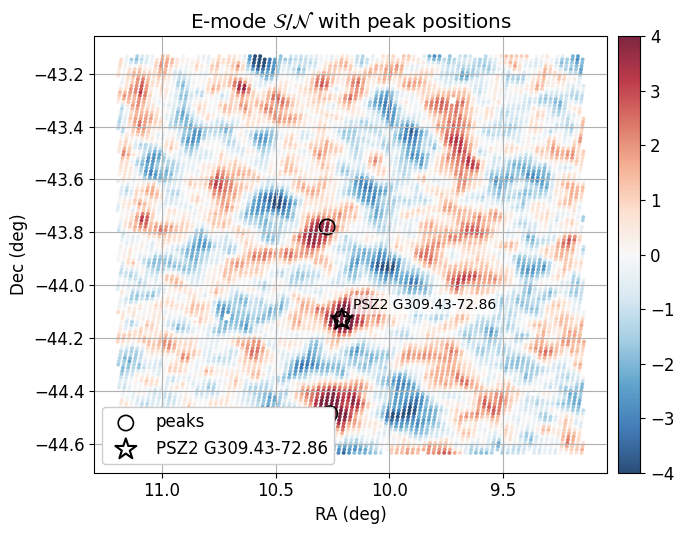

In [29]:
fig2, axp = plt.subplots(figsize=(7, 5.5))

# E-mode S/N on a fixed -4 to 4 scale so peak significance is directly readable.
sc = axp.scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_ratio_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-4,
    vmax=4,
    linewidths=0,
    alpha=0.85,
)

# Circle the detected peaks.
if peak_ipix.size:
    ra_peak, dec_peak = hp.pix2ang(nside, peak_ipix, nest=False, lonlat=True)
    axp.scatter(
        ra_peak,
        dec_peak,
        s=120,
        facecolors="none",
        edgecolors="k",
        linewidths=1.2,
        label="peaks",
    )
    print(ra_peak, dec_peak)

axp.set_xlabel("RA (deg)")
axp.set_ylabel("Dec (deg)")

# Planck SZ position of the target cluster.
mark_cluster(axp)
axp.grid()
axp.set_title(r"E-mode $\mathcal{S}/\mathcal{N}$ with peak positions")
axp.invert_xaxis()
fig2.colorbar(sc, ax=axp, fraction=0.046, pad=0.02)
axp.legend(loc="lower left", framealpha=1)
fig2.tight_layout()
save_plot(fig2, f"{CONFIG['TRACT']}_E-mode_sn_ratio")

### 6.5 Zoom on PSZ2 G309.43-72.86

E-mode S/N at cluster: 7.71  |  B-mode S/N: 2.13
Nearest peak: RA=10.2084, Dec=-44.1271, 0.21 arcmin from the cluster


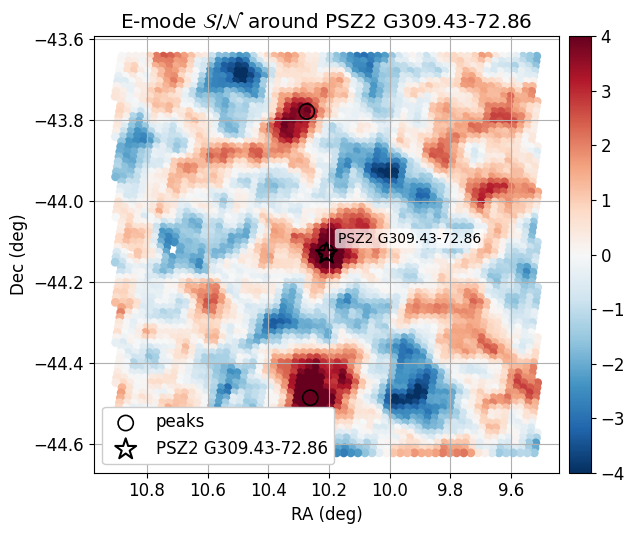

In [30]:
zoom_deg = 2.0 * CONFIG["RS_DEG"]  # Half-width of the zoom window
_cos = np.cos(np.deg2rad(CLUSTER["dec"]))


def near_cluster(ra, dec):
    return (np.abs(wrap_dra(ra, CLUSTER["ra"]) * _cos) < zoom_deg) & (np.abs(dec - CLUSTER["dec"]) < zoom_deg)


in_zoom = msk & near_cluster(ra_pix, dec_pix)

# S/N of the cell holding the cluster position, if it was evaluated.
_ip_cl = hp.ang2pix(nside, CLUSTER["ra"], CLUSTER["dec"], nest=False, lonlat=True)
_k_cl = np.flatnonzero(ipix_eval == _ip_cl)
if _k_cl.size:
    print(f"E-mode S/N at cluster: {sn_ratio_map[_k_cl[0]]:.2f}  |  B-mode S/N: {sn_bmode_map[_k_cl[0]]:.2f}")
else:
    print("Cluster cell was not evaluated (no selected galaxy in it)")

fig_z, axz = plt.subplots(figsize=(6.5, 5.5))
scz = axz.scatter(
    ra_pix[in_zoom],
    dec_pix[in_zoom],
    c=sn_ratio_map[in_zoom],
    s=max(1.0, min(40.0, 200_000.0 / max(int(in_zoom.sum()), 1))),
    cmap="RdBu_r",
    vmin=-4,
    vmax=4,
    linewidths=0,
)

# Nearest detected peak to the cluster.
if peak_ipix.size:
    ra_peak, dec_peak = hp.pix2ang(nside, peak_ipix, nest=False, lonlat=True)
    _sep = np.hypot(wrap_dra(ra_peak, CLUSTER["ra"]) * _cos, dec_peak - CLUSTER["dec"]) * 60.0
    _j = int(np.argmin(_sep))
    print(f"Nearest peak: RA={ra_peak[_j]:.4f}, Dec={dec_peak[_j]:.4f}, {_sep[_j]:.2f} arcmin from the cluster")
    _pz = near_cluster(ra_peak, dec_peak)
    axz.scatter(ra_peak[_pz], dec_peak[_pz], s=120, facecolors="none", edgecolors="k",
                linewidths=1.2, label="peaks")

mark_cluster(axz)
axz.set_xlabel("RA (deg)")
axz.set_ylabel("Dec (deg)")
axz.set_title(fr"E-mode $\mathcal{{S}}/\mathcal{{N}}$ around {CLUSTER['name']}")
axz.invert_xaxis()
axz.grid()
fig_z.colorbar(scz, ax=axz, fraction=0.046, pad=0.02)
axz.legend(loc="lower left", framealpha=1)
fig_z.tight_layout()
save_plot(fig_z, f"{CONFIG['TRACT']}_PSZ2_G309.43-72.86_zoom")

## 7.0 Filter and cell size

### 7.1 Analytic expectation

Consider a singular isothermal sphere (SIS) with Einstein radius θ_E, so that $\gamma_t(\theta) = \theta_E/2\theta$.
Averaging over all sources inside a circle of radius θ gives $\bar g_t(<\theta) = \theta_E/\theta$, with shape noise
$\sigma_g/\sqrt{n\pi\theta^2}$. The aperture S/N is then (Frieman 2026, eq. 5)

$$ \left(\frac{S}{N}\right)_{\rm top\text{-}hat} = \frac{\theta_E\sqrt{\pi n}}{\sigma_g}, $$

which does not depend on θ. A filter weighted as 1/θ, which the Schirmer filter is outside its core, reaches
$(S/N)^2 = (\pi n\theta_E^2/2\sigma_g^2)\ln(\theta_{\max}/\theta_{\min})$, so the S/N grows only logarithmically with aperture size.
For a real cluster this growth stops at large radius: the profile steepens beyond the NFW scale radius and r200, and
large-scale structure adds noise. At small radius, cluster members, blending, and strong lensing set the limit.

The S/N of a single map cell is, by comparison, $\gamma_t\sqrt{n A}/\sigma_g$. For a cell of area A = 1 arcmin² this is below 1
beyond a few arcmin of the cluster (computed below). The cell size therefore only sets where the statistic is sampled.
The detection S/N is set by the filter scale.

The next cell evaluates these expressions with the measured n_eff and σ_g, and fits θ_E (SIS) and the lensing efficiency
β (NFW, with the literature M200 and c = 4) to the profile from section 4.2.

In [31]:
from astropy.cosmology import FlatLambdaCDM
import astropy.constants as const
from scipy.optimize import curve_fit

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
D_L = cosmo.angular_diameter_distance(CLUSTER["z"])
ARCMIN_MPC = (D_L * (1 * u.arcmin).to(u.rad).value).to(u.Mpc).value
rho_c = cosmo.critical_density(CLUSTER["z"]).to(u.Msun / u.Mpc**3).value
R200_MPC = (3 * CLUSTER["M200"] / (4 * np.pi * 200 * rho_c)) ** (1 / 3)
print(f"z = {CLUSTER['z']}: 1' = {ARCMIN_MPC:.3f} Mpc;  r200 = {R200_MPC:.2f} Mpc = {R200_MPC / ARCMIN_MPC:.1f}'")


def nfw_gt(theta_arcmin, beta, M200=CLUSTER["M200"], c200=CLUSTER["c200"]):
    """NFW tangential shear (Wright & Brainerd 2000) for sources with lensing efficiency beta = <D_LS/D_S>."""
    r200 = (3 * M200 / (4 * np.pi * 200 * rho_c)) ** (1 / 3)
    rs = r200 / c200
    dc = 200 / 3 * c200**3 / (np.log(1 + c200) - c200 / (1 + c200))
    x = np.atleast_1d(np.asarray(theta_arcmin, float) * ARCMIN_MPC / rs)
    gfn = np.empty_like(x)
    lo, hi = x < 1, x > 1
    a = np.arctanh(np.sqrt((1 - x[lo]) / (1 + x[lo])))
    gfn[lo] = (8 * a / (x[lo] ** 2 * np.sqrt(1 - x[lo] ** 2)) + 4 / x[lo] ** 2 * np.log(x[lo] / 2)
               - 2 / (x[lo] ** 2 - 1) + 4 * a / ((x[lo] ** 2 - 1) * np.sqrt(1 - x[lo] ** 2)))
    b = np.arctan(np.sqrt((x[hi] - 1) / (1 + x[hi])))
    gfn[hi] = (8 * b / (x[hi] ** 2 * np.sqrt(x[hi] ** 2 - 1)) + 4 / x[hi] ** 2 * np.log(x[hi] / 2)
               - 2 / (x[hi] ** 2 - 1) + 4 * b / (x[hi] ** 2 - 1) ** 1.5)
    gfn[~(lo | hi)] = 10 / 3 + 4 * np.log(0.5)
    sig_crit = (const.c**2 / (4 * np.pi * const.G) / (D_L * beta)).to(u.Msun / u.Mpc**2).value
    return rs * dc * rho_c * gfn / sig_crit


# Fit the profile from 4.2 at theta > 1.5', outside the member-contaminated core.
rc, mt, mx, err = prof
fit = rc > 1.5
(thE,), cov = curve_fit(lambda t, a: a / (2 * t), rc[fit], mt[fit], sigma=err[fit], p0=[0.3], absolute_sigma=True)
(beta_fit,), covb = curve_fit(nfw_gt, rc[fit], mt[fit], sigma=err[fit], p0=[0.5], absolute_sigma=True)
print(f"SIS fit: theta_E = {thE:.3f} ± {np.sqrt(cov[0, 0]):.3f} arcmin")
for zs in (0.8, 1.0, 1.2):
    beta = (cosmo.angular_diameter_distance_z1z2(CLUSTER["z"], zs) / cosmo.angular_diameter_distance(zs)).value
    print(f"   -> sigma_v = {np.sqrt(np.deg2rad(thE / 60) / (4 * np.pi * beta)) * 3e5:.0f} km/s if all sources were at z_s = {zs} (beta = {beta:.2f})")
print(f"NFW fit with M200 = {CLUSTER['M200']:.1e}, c = {CLUSTER['c200']}: effective beta = {beta_fit:.2f} ± {np.sqrt(covb[0, 0]):.2f}")
print("   (beta below ~0.55 for z_s ~ 1 indicates dilution by foreground and cluster-member galaxies: there is no photo-z cut)")

print("\nAnalytic S/N with the measured n_eff and sigma_g:")
sn_tophat = thE * np.sqrt(np.pi * N_EFF) / SIGMA_G
print(f"   theta_E sqrt(pi n_eff)/sigma_g = {thE:.3f} x sqrt(pi x {N_EFF:.1f}) / {SIGMA_G:.3f} = {sn_tophat:.1f}  (top-hat, any radius)")
print(f"   per 1 arcmin^2 cell at theta = 2': S/N = {thE / 4 * np.sqrt(N_EFF) / SIGMA_G:.2f}")

z = 0.35: 1' = 0.296 Mpc;  r200 = 2.04 Mpc = 6.9'
SIS fit: theta_E = 0.246 ± 0.037 arcmin
   -> sigma_v = 1006 km/s if all sources were at z_s = 0.8 (beta = 0.51)
   -> sigma_v = 937 km/s if all sources were at z_s = 1.0 (beta = 0.58)
   -> sigma_v = 899 km/s if all sources were at z_s = 1.2 (beta = 0.63)
NFW fit with M200 = 1.4e+15, c = 4.0: effective beta = 0.36 ± 0.05
   (beta below ~0.55 for z_s ~ 1 indicates dilution by foreground and cluster-member galaxies: there is no photo-z cut)

Frieman eq. (5) with the measured numbers:
   theta_E sqrt(pi n_eff)/sigma_g = 0.246 x sqrt(pi x 17.8) / 0.344 = 5.3  (top-hat, any radius)
   per 1 arcmin^2 cell at theta = 2': S/N = 0.75


### 7.2 S/N against filter scale

For each aperture radius Rs, and three values of the core radius x_c, we compute:

* **measured**: the E-mode S/N at the SZ position, using the aperture function from the map;
* **predicted**: the same statistic with $g_t$ replaced by the fitted NFW (or SIS) shear, with the noise term computed from
  the real source positions, weights, and ellipticities, so masks and depth variations are included;
* **noise peaks**: the highest peak in the tract in random-rotation noise maps, using NSIDE = 1024 for speed. Coarse cells
  undersample the peaks, so these values run about 0.5 below the NSIDE = 4096 values in section 5. They are for comparing
  one Rs with another.

S/N values at neighboring Rs are strongly correlated, and the cluster S/N has a statistical scatter of about ±1.

In [32]:
RS_GRID = np.array([2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25])
XC_GRID = [0.05, 0.15, 0.3]
_cdeg = (CLUSTER["ra"], CLUSTER["dec"])
_idx_cl = np.asarray(tree.query_ball_point(radec_to_xyz(*_cdeg)[0], r=chord_radius(1.25 * RS_GRID.max() / 60)))


def sn_at_cluster(rs_arcmin, xc, g1_=None, g2_=None):
    g1_ = g1 if g1_ is None else g1_
    g2_ = g2 if g2_ is None else g2_
    return aperture_mass_and_sn_at_center(*_cdeg, ra_deg[_idx_cl], dec_deg[_idx_cl], g1_[_idx_cl], g2_[_idx_cl],
                                          theta_max_arcmin=1.2 * rs_arcmin, rs_deg=rs_arcmin / 60, w_all=w_gal[_idx_cl], xc=xc)


def predicted_sn(rs_arcmin, xc, model):
    """S/N of a noiseless model shear field sampled at the real source positions with the real noise denominator."""
    x = wrap_dra(ra_deg[_idx_cl], _cdeg[0]) * np.cos(np.deg2rad(_cdeg[1])) * 60
    y = (dec_deg[_idx_cl] - _cdeg[1]) * 60
    r = np.hypot(x, y)
    s = r <= 1.2 * rs_arcmin
    q = schirmer_weight(r[s], rs_arcmin, xc)
    ws = w_gal[_idx_cl][s]
    den = np.sqrt(np.sum(q**2 * ws**2 * (g1[_idx_cl][s] ** 2 + g2[_idx_cl][s] ** 2)) / 2)
    return np.sum(q * ws * model(np.maximum(r[s], 0.05))) / den


sweep = {xc: np.array([sn_at_cluster(rs, xc)[1] for rs in RS_GRID]) for xc in XC_GRID}
sweep_B = np.array([sn_at_cluster(rs, CONFIG["FILTER_XC"])[3] for rs in RS_GRID])
pred_nfw = np.array([predicted_sn(rs, CONFIG["FILTER_XC"], lambda t: nfw_gt(t, beta_fit)) for rs in RS_GRID])
pred_sis = np.array([predicted_sn(rs, CONFIG["FILTER_XC"], lambda t: thE / (2 * t)) for rs in RS_GRID])

# Coarse noise-only maps per Rs: highest random-rotation peak in the tract (shape noise only).
NSIDE_SWEEP, N_RAND_SWEEP = 1024, 10
noise_max = []
for rs in tqdm(RS_GRID, desc="noise maps per Rs"):
    nm = run_aperture_map(NSIDE_SWEEP, rs / 60, 1.2 * rs, n_random=N_RAND_SWEEP, seed=1, progress=False)
    _kw = dict(nside=NSIDE_SWEEP, excl_radius_arcmin=CONFIG["PEAK_EXCL_RS_MULT"] * rs, completeness_min=CONFIG["PEAK_COMPLETENESS_MIN"])
    _io = {int(p): k for k, p in enumerate(nm["ipix"])}
    mx_ = []
    for j in range(N_RAND_SWEEP):
        pk_ = find_peaks_shear_healpix(nm["ipix"], nm["sn_rand"][:, j], nm["completeness"], **_kw)
        mx_.append(np.nanmax(nm["sn_rand"][[_io[int(p)] for p in pk_], j]) if pk_.size else np.nan)
    good_ = nm["completeness"] >= CONFIG["PEAK_COMPLETENESS_MIN"]
    _ra_n, _dec_n = hp.pix2ang(NSIDE_SWEEP, nm["ipix"], lonlat=True)
    _sep_n = np.hypot(wrap_dra(_ra_n, _cdeg[0]) * np.cos(np.deg2rad(_cdeg[1])), _dec_n - _cdeg[1]) * 60
    far_ = good_ & (_sep_n > max(2 * rs, 10))
    noise_max.append((np.nanmean(mx_), np.nanpercentile(mx_, 90), np.nanstd(nm["sn_e"][far_]) if far_.sum() > 20 else np.nan))
noise_max = np.array(noise_max)

print(" Rs[']  S/N(xc=.05)  S/N(xc=.15)  S/N(xc=.3)  B(xc=.15)  pred_NFW  pred_SIS  noise-max(mean/90%)  std(E far)")
for i, rs in enumerate(RS_GRID):
    print(f"{rs:6.0f}  {sweep[0.05][i]:10.2f}  {sweep[0.15][i]:11.2f}  {sweep[0.3][i]:10.2f}  {sweep_B[i]:9.2f}  "
          f"{pred_nfw[i]:8.2f}  {pred_sis[i]:8.2f}  {noise_max[i, 0]:9.2f} / {noise_max[i, 1]:.2f}  {noise_max[i, 2]:9.2f}")

noise maps per Rs:   0%|          | 0/11 [00:00<?, ?it/s]

noise maps per Rs:   9%|▉         | 1/11 [00:00<00:03,  3.14it/s]

noise maps per Rs:  18%|█▊        | 2/11 [00:00<00:03,  2.69it/s]

noise maps per Rs:  27%|██▋       | 3/11 [00:01<00:03,  2.37it/s]

noise maps per Rs:  36%|███▋      | 4/11 [00:01<00:03,  1.97it/s]

...

noise maps per Rs:  82%|████████▏ | 9/11 [00:10<00:03,  1.94s/it]

noise maps per Rs:  91%|█████████ | 10/11 [00:16<00:03,  3.05s/it]

noise maps per Rs: 100%|██████████| 11/11 [00:23<00:00,  4.50s/it]

noise maps per Rs: 100%|██████████| 11/11 [00:23<00:00,  2.17s/it]

 Rs[']  S/N(xc=.05)  S/N(xc=.15)  S/N(xc=.3)  B(xc=.15)  pred_NFW  pred_SIS  noise-max(mean/90%)  std(E far)
     2        4.57         4.67        4.72      -0.30      2.69      4.75       3.09 / 3.63       1.01
     3        5.26         5.37        5.29      -0.30      3.87      5.51       3.00 / 3.30       1.02
     4        6.04         6.14        6.01       0.20      4.64      5.88       2.98 / 3.25       1.05
     5        6.64         6.72        6.57       0.57      5.19      6.15       2.94 / 3.21       1.06
     6        7.13         7.13        6.95       1.20      5.58      6.29       3.06 / 3.41       1.08
     8        7.48         7.30        7.04       1.62      6.06      6.37       2.93 / 3.43       1.13
    10        7.41         7.17        6.85       1.91      6.35      6.40       2.92 / 3.26       1.16
    12        7.44         7.23        6.87       2.20      6.54      6.45       2.89 / 3.28       1.17
    15        7.79         7.60        7.23       2.24     

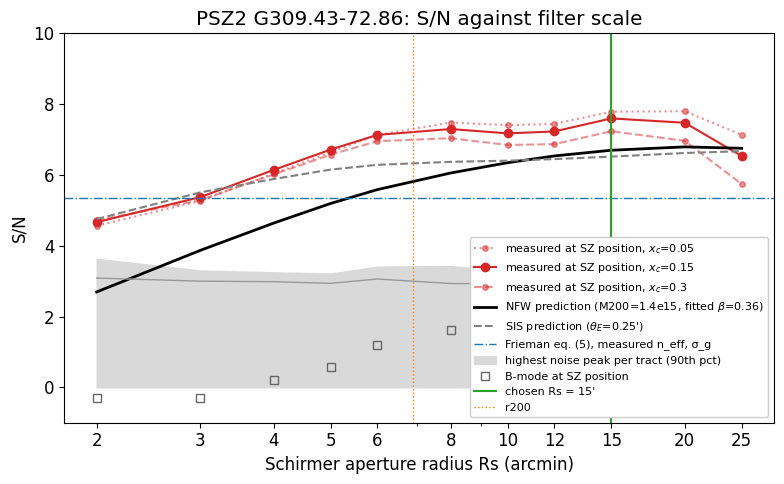

In [33]:
fig_s, ax_s = plt.subplots(figsize=(8, 5))
for xc, ls in zip(XC_GRID, [":", "-", "--"]):
    ax_s.plot(RS_GRID, sweep[xc], "o" + ls, color="C3", ms=4 if xc != CONFIG["FILTER_XC"] else 6,
              alpha=1 if xc == CONFIG["FILTER_XC"] else 0.5, label=f"measured at SZ position, $x_c$={xc}")
ax_s.plot(RS_GRID, pred_nfw, "-", color="k", lw=2, label=fr"NFW prediction (M200=1.4e15, fitted $\beta$={beta_fit:.2f})")
ax_s.plot(RS_GRID, pred_sis, "--", color="0.5", label=fr"SIS prediction ($\theta_E$={thE:.2f}')")
ax_s.axhline(sn_tophat, color="C0", ls="-.", lw=1, label="Frieman eq. (5), measured n_eff, σ_g")
ax_s.fill_between(RS_GRID, 0, noise_max[:, 1], color="0.85", label="highest noise peak per tract (90th pct)")
ax_s.plot(RS_GRID, noise_max[:, 0], color="0.6", lw=1)
ax_s.plot(RS_GRID, sweep_B, "s", mfc="none", color="0.4", label="B-mode at SZ position")
ax_s.axvline(CONFIG["RS_ARCMIN"], color="C2", lw=1.5, label=f"chosen Rs = {CONFIG['RS_ARCMIN']:.0f}'")
ax_s.axvline(R200_MPC / ARCMIN_MPC, color="C1", lw=1, ls=":", label="r200")
ax_s.set_xscale("log")
ax_s.set_xticks(RS_GRID)
ax_s.set_xticklabels([str(r) for r in RS_GRID])
ax_s.set_xlabel("Schirmer aperture radius Rs (arcmin)")
ax_s.set_ylabel("S/N")
ax_s.set_ylim(-1, 10)
ax_s.legend(fontsize=8, loc="lower right", framealpha=1)
ax_s.set_title(f"{CLUSTER['name']}: S/N against filter scale")
fig_s.tight_layout()
save_plot(fig_s, f"{CONFIG['TRACT']}_PSZ2_G309_sn_vs_rs")

### 7.3 Choice of filter and cell size

We measure aperture-mass statistics with the Schirmer et al. (2007) filter. It is flat inside a core of radius x_c Rs, falls
as 1/θ outside it (the matched filter for an isothermal shear profile), and is truncated at θ ≈ Rs. Two scales are involved.
The filter radius Rs sets the signal-to-noise. The HEALPix cell size sets only how finely the S/N field is sampled. We choose
them separately.

**Filter scale.** For an isothermal lens, the S/N of a matched aperture grows only as $\sqrt{\ln(R_s/\theta_{\min})}$, and for
an NFW lens it saturates once the aperture extends past r200. With the measured source density
(n_eff ≈ 18 arcmin⁻²) and per-component shape noise (σ_g ≈ 0.34), the NFW profile fitted to the tangential shear of
PSZ2 G309.43-72.86 predicts an S/N that rises steeply up to Rs ≈ r200 ≈ 7′ and stays within 5% of its maximum for
Rs ≈ 11–25′. The measured S/N at the cluster follows the same curve and is highest at Rs = 15–20′ (S/N ≈ 7.5–7.8).
Larger apertures add noise from uncorrelated large-scale structure. The scatter of the E-mode S/N map away from the
cluster grows from 1.2 at Rs = 15′ to 1.45 at 20′, compared with 1.0 for shape noise alone. Larger apertures also
lose more area at survey edges and blend neighboring halos. We therefore adopt **Rs = 15′** (≈ 2.2 r200). The core radius
has little effect: x_c from 0.05 to 0.3 changes the S/N by less than 0.5. We keep the NFW-optimized value
**x_c = 0.15**. Because the optimal aperture scales with r200 ∝ M^{1/3}, a blind search for lower-mass clusters
(M200 ~ 3×10¹⁴ M⊙, r200 ~ 4′ at z ≈ 0.3) would use Rs ≈ 6–10′.

**Cell size.** The S/N peak at the cluster is sharp, with a half-width of about 1.5′ set by the filter core. It must be
sampled on a grid fine enough that some cell center falls near the maximum. Cell spacing s gives a worst-case
offset of about s/√2. On cells of NSIDE = 4096 (0.86′) this costs at most ≈ 0.7σ and typically ≈ 0.2σ. NSIDE = 2048 and
1024 cost up to ≈ 1.8σ and ≈ 3.7σ, and NSIDE = 8192 gains only ≈ 0.2σ for four times the cost. We adopt **NSIDE = 4096**.

**Peak definition.** Peaks are maxima of the S/N map, not of M_ap, so that regions with fewer sources do not produce
spuriously large M_ap values. The exclusion radius is 0.4 Rs, where the autocorrelation of the noise maps drops to about
0.1 (half-width ≈ 0.2 Rs). Apertures must be at least 80% complete. The threshold is S/N ≥ 4, above the highest peak in every
random-rotation realization of the tract (mean highest peak ≈ 3.4).

With these choices, PSZ2 G309.43-72.86 is the highest peak in the tract (S/N ≈ 7.7, 0.2′ from the SZ position). This agrees
with the analytic expectation once the measured n_eff and σ_g are used.